# **Part I: Data Cleaning & EDA**

## 1.1 System setup

In [ ]:
from pathlib import Path

# Colab reads the files from Google Drive.
# Anywhere else, read the copies in data/raw of the repo.
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')
    PROJECT_DIR = Path('/content/drive/MyDrive/SIADS_696_project')
else:
    import matplotlib
    matplotlib.use("Agg")
    PROJECT_DIR = None
    folders = [Path.cwd(), *Path.cwd().parents]
    try:
        folders.extend(Path(__file__).resolve().parents)
    except NameError:
        pass
    for folder in folders:
        if (folder / 'data' / 'raw' / 'TCGA-CDR-SupplementalTableS1.xlsx').exists():
            PROJECT_DIR = folder
            break
    if PROJECT_DIR is None:
        raise FileNotFoundError("Could not find data/raw. Open this notebook from inside the repo folder.")

RAW_DIR = PROJECT_DIR / 'data' / "raw"
PROCESSED_DIR = PROJECT_DIR / 'data' / "processed"

FIGURE_DIR = PROJECT_DIR / 'outputs' / 'figures'
TABLE_DIR = PROJECT_DIR / 'outputs' / 'tables'

# Create output folders if they do not already exist
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Raw data folder:", RAW_DIR)
print("Files in raw data folder:")

for file in RAW_DIR.iterdir():
    print("-", file.name)
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Raw data folder: /content/drive/MyDrive/SIADS_696_project/data/raw
Files in raw data folder:
- TCGA.Kallisto.fullIDs.cibersort.relative.tsv
- TCGA-CDR-SupplementalTableS1.xlsx


## 1.2 Import File

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

CDR_FILE = RAW_DIR / "TCGA-CDR-SupplementalTableS1.xlsx"
IMMUNE_FILE = RAW_DIR / "TCGA.Kallisto.fullIDs.cibersort.relative.tsv"

cdr = pd.read_excel(
    CDR_FILE,
    sheet_name="TCGA-CDR"
)

immune = pd.read_csv(
    IMMUNE_FILE,
    sep="\t"
)

print("Clinical dataset:", cdr.shape)
print("Immune dataset:", immune.shape)

display(cdr.head())
display(immune.head())

Clinical dataset: (11160, 34)
Immune dataset: (11373, 27)


,Unnamed: 0,bcr_patient_barcode,type,age_at_initial_pathologic_diagnosis,gender,race,ajcc_pathologic_tumor_stage,clinical_stage,histological_type,histological_grade,...,residual_tumor,OS,OS.time,DSS,DSS.time,DFI,DFI.time,PFI,PFI.time,Redaction
0,1,TCGA-OR-A5J1,ACC,58.0,MALE,WHITE,Stage II,[Not Applicable],Adrenocortical carcinoma- Usual Type,[Not Available],...,NaN,1.0,1355.0,1.0,1355.0,1.0,754.0,1.0,754.0,NaN
1,2,TCGA-OR-A5J2,ACC,44.0,FEMALE,WHITE,Stage IV,[Not Applicable],Adrenocortical carcinoma- Usual Type,[Not Available],...,NaN,1.0,1677.0,1.0,1677.0,NaN,NaN,1.0,289.0,NaN
2,3,TCGA-OR-A5J3,ACC,23.0,FEMALE,WHITE,Stage III,[Not Applicable],Adrenocortical carcinoma- Usual Type,[Not Available],...,NaN,0.0,2091.0,0.0,2091.0,1.0,53.0,1.0,53.0,NaN
3,4,TCGA-OR-A5J4,ACC,23.0,FEMALE,WHITE,Stage IV,[Not Applicable],Adrenocortical carcinoma- Usual Type,[Not Available],...,NaN,1.0,423.0,1.0,423.0,NaN,NaN,1.0,126.0,NaN
4,5,TCGA-OR-A5J5,ACC,30.0,MALE,WHITE,Stage III,[Not Applicable],Adrenocortical carcinoma- Usual Type,[Not Available],...,NaN,1.0,365.0,1.0,365.0,NaN,NaN,1.0,50.0,NaN


,SampleID,CancerType,B.cells.naive,B.cells.memory,Plasma.cells,T.cells.CD8,T.cells.CD4.naive,T.cells.CD4.memory.resting,T.cells.CD4.memory.activated,T.cells.follicular.helper,...,Macrophages.M2,Dendritic.cells.resting,Dendritic.cells.activated,Mast.cells.resting,Mast.cells.activated,Eosinophils,Neutrophils,P.value,Correlation,RMSE
0,TCGA.OR.A5JG.01A.11R.A29S.07,ACC,0.000000,0.048529,0.016052,0.046099,0.027037,0.290682,0.0,0.000000,...,0.363861,0.002715,0.026125,0.032788,0.000000,0.010290,0.009607,0.112,0.095797,1.047142
1,TCGA.OR.A5LG.01A.11R.A29S.07,ACC,0.007169,0.011125,0.007982,0.139842,0.000000,0.142742,0.0,0.001614,...,0.448243,0.000000,0.007464,0.126237,0.000000,0.000000,0.000000,0.104,0.103345,1.046163
2,TCGA.OR.A5JD.01A.11R.A29S.07,ACC,0.000023,0.014607,0.000000,0.104888,0.000000,0.174895,0.0,0.017928,...,0.329552,0.000000,0.009330,0.000000,0.190730,0.000000,0.000000,0.068,0.143259,1.039812
3,TCGA.OR.A5LH.01A.11R.A29S.07,ACC,0.047299,0.038180,0.000000,0.198591,0.000000,0.065240,0.0,0.043310,...,0.287939,0.000000,0.000576,0.000000,0.064725,0.000000,0.000000,0.388,0.028763,1.080553
4,TCGA.OR.A5KY.01A.11R.A29S.07,ACC,0.000000,0.024795,0.004418,0.051506,0.000000,0.225892,0.0,0.000000,...,0.486400,0.000000,0.042827,0.000000,0.017418,0.014769,0.000000,0.246,0.055621,1.073474


The clinical dataset contains 11,160 records and 34 variables. The immune dataset contains 11,373 samples and 27 variables, including 22 immune cell proportions and three CIBERSORT quality measures.

## 1.3 Data Cleaning

In [ ]:
# Keep only KIRC patients in the clinical dataset
cdr_kirc = cdr.loc[cdr["type"] == "KIRC"].copy()

# Rename the patient ID column
cdr_kirc = cdr_kirc.rename(columns={"bcr_patient_barcode": "patient_id"})

# Keep only KIRC samples in the immune dataset
immune_kirc = immune.loc[immune["CancerType"] == "KIRC"].copy()

print("KIRC clinical patients:", len(cdr_kirc))
print("KIRC immune samples:", len(immune_kirc))
print("KIRC clinical patients columns:", cdr_kirc.columns)
print("KIRC immune samples columns:", immune_kirc.columns)

KIRC clinical patients: 537
KIRC immune samples: 618
KIRC clinical patients columns: Index(['Unnamed: 0', 'patient_id', 'type',
       'age_at_initial_pathologic_diagnosis', 'gender', 'race',
       'ajcc_pathologic_tumor_stage', 'clinical_stage', 'histological_type',
       'histological_grade', 'initial_pathologic_dx_year', 'menopause_status',
       'birth_days_to', 'vital_status', 'tumor_status', 'last_contact_days_to',
       'death_days_to', 'cause_of_death', 'new_tumor_event_type',
       'new_tumor_event_site', 'new_tumor_event_site_other',
       'new_tumor_event_dx_days_to', 'treatment_outcome_first_course',
       'margin_status', 'residual_tumor', 'OS', 'OS.time', 'DSS', 'DSS.time',
       'DFI', 'DFI.time', 'PFI', 'PFI.time', 'Redaction'],
      dtype='object')
KIRC immune samples columns: Index(['SampleID', 'CancerType', 'B.cells.naive', 'B.cells.memory',
       'Plasma.cells', 'T.cells.CD8', 'T.cells.CD4.naive',
       'T.cells.CD4.memory.resting', 'T.cells.CD4.memory.ac

In [ ]:
# Standardize TCGA sample ID format
immune_kirc["sample_barcode"] = (
    immune_kirc["SampleID"]
    .astype(str)
    .str.replace(".", "-", regex=False)
)

# TCGA-XX-XXXX-01A becomes patient TCGA-XX-XXXX
immune_kirc["patient_id"] = (
    immune_kirc["sample_barcode"]
    .str.extract(r"^(TCGA-[^-]+-[^-]+)")
)

# Extract sample type: 01 means primary tumor
immune_kirc["sample_type"] = (
    immune_kirc["sample_barcode"]
    .str.extract(r"^TCGA-[^-]+-[^-]+-(\d{2})")
)

# Keep primary tumor samples only
immune_primary = immune_kirc.loc[
    immune_kirc["sample_type"] == "01"
].copy()

print("Primary tumor samples:", len(immune_primary))
print(
    "Patients with primary tumors:",
    immune_primary["patient_id"].nunique()
)

Primary tumor samples: 545
Patients with primary tumors: 533


After selecting KIRC cases, 537 clinical patients and 618 immune samples remained. After keeping only primary tumor samples, there were 545 samples from 533 unique patients.

In [ ]:
# Save patients who have more than one primary tumor sample
duplicate_samples = immune_primary.loc[
    immune_primary.duplicated(
        "patient_id",
        keep=False
    )
].sort_values("patient_id")

duplicate_samples.to_csv(
    TABLE_DIR / "duplicate_primary_samples.csv",
    index=False
)

# Choose one sample per patient
immune_patient = (
    immune_primary
    .sort_values(
        [
            "patient_id",
            "P.value",
            "RMSE",
            "Correlation",
            "SampleID"
        ],
        ascending=[
            True,   # patient ID
            True,   # lower P-value is preferred
            True,   # lower RMSE is preferred
            False,  # higher correlation is preferred
            True    # final consistent tie-breaker
        ]
    )
    .drop_duplicates(
        "patient_id",
        keep="first"
    )
    .copy()
)

print("Patients after removing duplicates:", len(immune_patient))
print(
    "Remaining duplicate patients:",
    immune_patient["patient_id"].duplicated().sum()
)

Patients after removing duplicates: 533
Remaining duplicate patients: 0


Some patients had more than one primary tumor sample. For these patients, one sample was selected using lower P-value, lower RMSE, and higher correlation. This process left one immune sample for each of the 533 patients.

In [ ]:
# check clinical missing values
variables_to_check = [
    "gender",
    "ajcc_pathologic_tumor_stage",
    "histological_grade",
]

for column in variables_to_check:
    print("\nVariable:", column)
    print("Data type:", cdr_kirc[column].dtype)
    print("Actual missing values:", cdr_kirc[column].isna().sum())
    print("Number of unique values:", cdr_kirc[column].nunique(dropna=False))

    display(
        cdr_kirc[column]
        .value_counts(dropna=False)
        .head(30)
    )



Variable: gender
Data type: object
Actual missing values: 0
Number of unique values: 2


,count
gender,
MALE,346
FEMALE,191



Variable: ajcc_pathologic_tumor_stage
Data type: object
Actual missing values: 0
Number of unique values: 5


,count
ajcc_pathologic_tumor_stage,
Stage I,269
Stage III,125
Stage IV,83
Stage II,57
[Discrepancy],3



Variable: histological_grade
Data type: object
Actual missing values: 0
Number of unique values: 6


,count
histological_grade,
G2,230
G3,207
G4,78
G1,14
GX,5
[Not Available],3


Gender had no missing values. Pathologic stage had three invalid values, and histological grade had eight unavailable or unknown values. These values were changed to missing values so they could be imputed later inside the modeling pipeline.

In [ ]:
# check clinical numeric missing values
numeric_variables = [
    "age_at_initial_pathologic_diagnosis",
    "OS",
    "OS.time"
]

for column in numeric_variables:

    numeric_version = pd.to_numeric(
        cdr_kirc[column],
        errors="coerce"
    )

    invalid_values = cdr_kirc.loc[
        cdr_kirc[column].notna() &
        numeric_version.isna(),
        column
    ]

    print("\nNon-numeric values in", column)

    if len(invalid_values) == 0:
        print("No non-numeric values were found.")
    else:
        display(invalid_values.value_counts())


Non-numeric values in age_at_initial_pathologic_diagnosis
No non-numeric values were found.

Non-numeric values in OS
No non-numeric values were found.

Non-numeric values in OS.time
No non-numeric values were found.


In [ ]:
# keep nessary clinical variables
clinical_columns = [
    "patient_id",
    "age_at_initial_pathologic_diagnosis",
    "gender",
    "ajcc_pathologic_tumor_stage",
    "histological_grade",
    "OS",
    "OS.time"
]

clinical = cdr_kirc[clinical_columns].copy()

missing_values = [
    "[Not Available]",
    "[Discrepancy]",
    "GX",
]

clinical = clinical.replace(
    missing_values,
    np.nan
)

clinical[
    "age_at_initial_pathologic_diagnosis"
] = pd.to_numeric(
    clinical["age_at_initial_pathologic_diagnosis"],
    errors="coerce"
)

clinical["OS"] = pd.to_numeric(
    clinical["OS"],
    errors="coerce"
)

clinical["OS.time"] = pd.to_numeric(
    clinical["OS.time"],
    errors="coerce"
)

In [ ]:
missing_summary = pd.DataFrame({
    "missing_count": clinical.isna().sum(),
    "missing_percent": clinical.isna().mean() * 100
}).sort_values(
    "missing_percent",
    ascending=False
)

display(missing_summary)

,missing_count,missing_percent
histological_grade,8,1.489758
ajcc_pathologic_tumor_stage,3,0.558659
patient_id,0,0.000000
gender,0,0.000000
age_at_initial_pathologic_diagnosis,0,0.000000
OS,0,0.000000
OS.time,0,0.000000


## 1.4 Merge Clinical and Immune Data

In [ ]:
merged = clinical.merge(
    immune_patient,
    on="patient_id",
    how="inner",
    validate="one_to_one"
)

print("Patients after merging:", len(merged))
display(merged.head())

Patients after merging: 533


,patient_id,age_at_initial_pathologic_diagnosis,gender,ajcc_pathologic_tumor_stage,histological_grade,OS,OS.time,SampleID,CancerType,B.cells.naive,...,Dendritic.cells.activated,Mast.cells.resting,Mast.cells.activated,Eosinophils,Neutrophils,P.value,Correlation,RMSE,sample_barcode,sample_type
0,TCGA-3Z-A93Z,69.0,MALE,Stage I,G2,0.0,385.0,TCGA.3Z.A93Z.01A.11R.A37O.07,KIRC,0.076633,...,0.000223,0.030092,0.000000,0.0,0.000000,0.002,0.324338,0.951231,TCGA-3Z-A93Z-01A-11R-A37O-07,01
1,TCGA-6D-AA2E,68.0,FEMALE,Stage I,G2,0.0,362.0,TCGA.6D.AA2E.01A.11R.A37O.07,KIRC,0.139206,...,0.000000,0.000000,0.031692,0.0,0.000000,0.000,0.401314,0.920127,TCGA-6D-AA2E-01A-11R-A37O-07,01
2,TCGA-A3-3306,67.0,MALE,Stage I,G3,0.0,1120.0,TCGA.A3.3306.01A.01R.0864.07,KIRC,0.000000,...,0.000000,0.021969,0.000000,0.0,0.017851,0.056,0.134451,1.035928,TCGA-A3-3306-01A-01R-0864-07,01
3,TCGA-A3-3307,66.0,MALE,Stage III,G3,0.0,1436.0,TCGA.A3.3307.01A.01R.0864.07,KIRC,0.005329,...,0.000000,0.018104,0.000000,0.0,0.007902,0.006,0.286399,0.970391,TCGA-A3-3307-01A-01R-0864-07,01
4,TCGA-A3-3308,77.0,FEMALE,Stage III,G2,0.0,16.0,TCGA.A3.3308.01A.02R.1325.07,KIRC,0.032737,...,0.000000,0.027088,0.000000,0.0,0.000000,0.036,0.160134,1.024322,TCGA-A3-3308-01A-02R-1325-07,01


The clinical and immune datasets were merged by patient ID. The final merged dataset contained 533 patients, with one record for each patient.

## 1.5 Define Valid 3-Years Survival Patient Groups



In [ ]:
DAYS_3Y = 365 * 3

died_within_3y = (
    (merged["OS"] == 1) &
    (merged["OS.time"] <= DAYS_3Y)
)

survived_3y = (
    (merged["OS.time"] > DAYS_3Y) |
    (
        (merged["OS"] == 0) &
        (merged["OS.time"] >= DAYS_3Y)
    )
)

# Define valid 3-years survival patient groups
# 0 = died within 3 years, 1 = survived within 3 years,
# others = nan
merged["survival_3y"] = np.select(
    [died_within_3y, survived_3y],
    [0, 1],
    default=np.nan
)

# Supervised, only keep data having valid 3-years survival records
supervised = merged.loc[
    merged["survival_3y"].notna()
].copy()

supervised["survival_3y"] = (
    supervised["survival_3y"].astype(int)
)

print(supervised["survival_3y"].value_counts())

survival_3y
1    293
0    111
Name: count, dtype: int64


A total of 404 patients had a known three-year survival outcome. Among them, 293 survived for at least three years and 111 died within three years. Another 129 patients were excluded from supervised learning because they were alive but had less than three years of follow-up.

## 1.6 Save Files

In [ ]:
merged.to_csv(
    PROCESSED_DIR / "kirc_patient_level_merged.csv",
    index=False
)

supervised.to_csv(
    PROCESSED_DIR / "kirc_supervised_3year.csv",
    index=False
)


## 1.7 Explortory Data Analysis

In [ ]:
# Confirm each row is one patient
print('Duplicated patients in merged dataset:', merged.duplicated('patient_id').sum())
print('Duplicated patients in supervised dataset:', supervised.duplicated('patient_id').sum())


Duplicated patients in merged dataset: 0
Duplicated patients in supervised dataset: 0


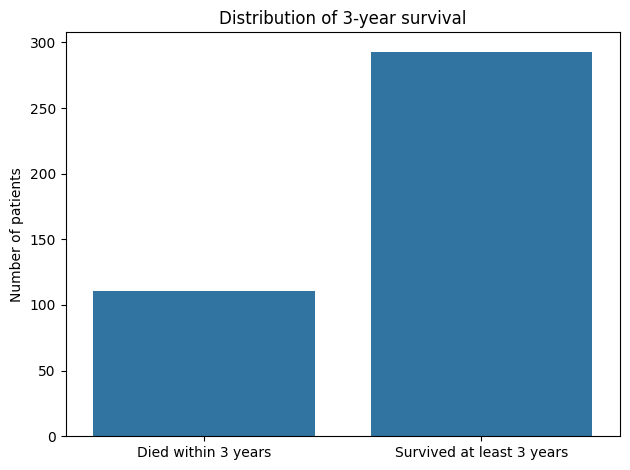

survival_3y
1    293
0    111
Name: count, dtype: int64


In [ ]:
# Display 3-year patient label counts
sns.countplot(data=supervised, x='survival_3y')

plt.xticks(
    [0, 1],
    ['Died within 3 years', 'Survived at least 3 years'])

plt.xlabel("")
plt.ylabel("Number of patients")
plt.title("Distribution of 3-year survival")
plt.tight_layout()

plt.savefig(FIGURE_DIR / "3year_survival_distribution.png")

plt.show()

print(supervised["survival_3y"].value_counts())

The outcome classes are not balanced. About 72.5% of the patients survived for at least three years, while about 27.5% died within three years. Because of this imbalance, accuracy alone may give a misleading evaluation.

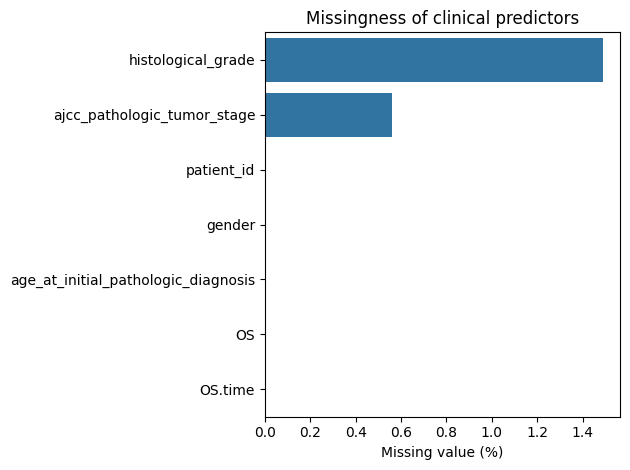

,missing_count,missing_percent
histological_grade,8,1.489758
ajcc_pathologic_tumor_stage,3,0.558659
patient_id,0,0.000000
gender,0,0.000000
age_at_initial_pathologic_diagnosis,0,0.000000
OS,0,0.000000
OS.time,0,0.000000


In [ ]:
# Display missing value summary

sns.barplot(
    data=missing_summary,
    y=missing_summary.index,
    x=missing_summary["missing_percent"])

plt.ylabel("")
plt.xlabel("Missing value (%)")
plt.title("Missingness of clinical predictors")
plt.tight_layout()

plt.savefig(FIGURE_DIR / "missing_value_summary.png")

plt.show()

display(missing_summary)

Missingness was low among the clinical predictors. Histological grade had about 1.5% missing values, and pathologic stage had about 0.6% missing values. Age and gender had no missing values.

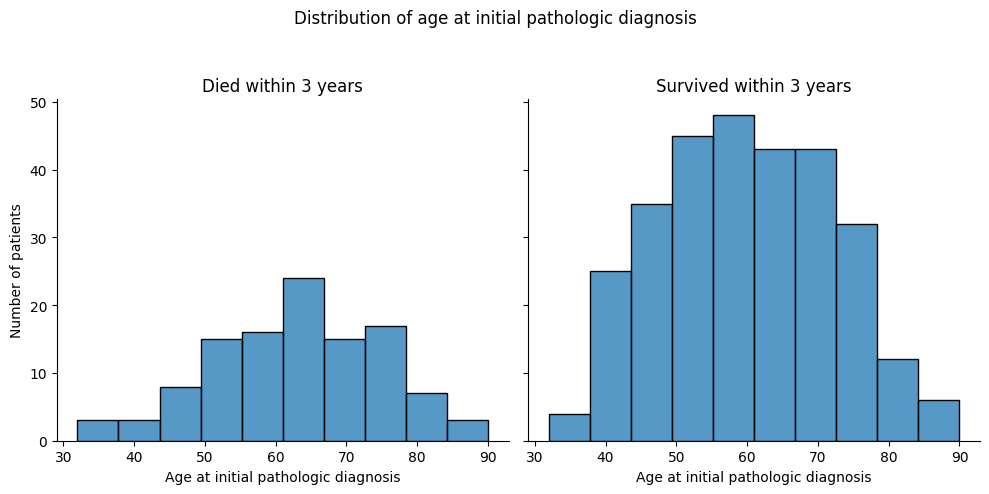

In [ ]:
# Distribution - Age

g = sns.displot(
    data=supervised,
    x="age_at_initial_pathologic_diagnosis",
    col="survival_3y",
    bins=10,
)

for ax in g.axes.flat:
    old_title = ax.get_title()
    if "0" in old_title:
        ax.set_title("Died within 3 years")
    elif "1" in old_title:
        ax.set_title("Survived within 3 years")

g.set_axis_labels(
    "Age at initial pathologic diagnosis", "Number of patients"
)

g.fig.subplots_adjust(top=0.8)
g.fig.suptitle("Distribution of age at initial pathologic diagnosis")

plt.savefig(FIGURE_DIR / "age_distribution.png", bbox_inches="tight")
plt.show()



The age distributions of the two survival groups overlap substantially. Most patients in both groups were middle-aged or older. Age may provide useful information, but it cannot clearly separate the two outcomes by itself.

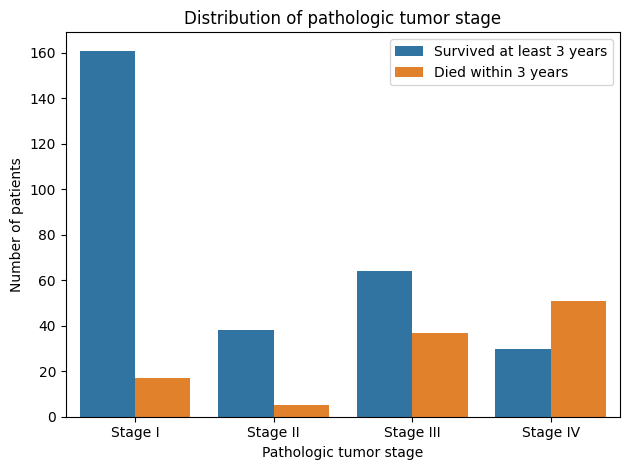

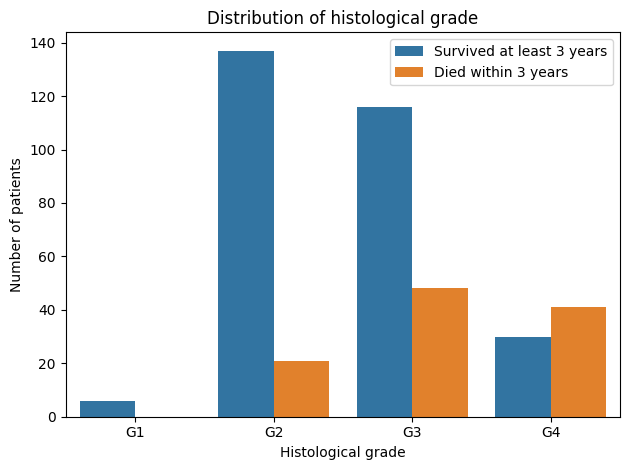

In [ ]:
# Distribution - Stage
survival_map = {0: "Died within 3 years", 1: "Survived at least 3 years"}
supervised["survival_3y_label"] = supervised["survival_3y"].map(survival_map)

stage_order = ["Stage I", "Stage II", "Stage III", "Stage IV"]
grade_order = ["G1", "G2", "G3", "G4"]

actual_stage_order = [
    s for s in stage_order if s in supervised["ajcc_pathologic_tumor_stage"].unique()
]

actual_grade_order = [
    g for g in grade_order if g in supervised["histological_grade"].unique()
]

sns.countplot(
    data=supervised,
    x="ajcc_pathologic_tumor_stage",
    hue="survival_3y_label",
    order=actual_stage_order
)

plt.xlabel("Pathologic tumor stage")
plt.ylabel("Number of patients")
plt.title("Distribution of pathologic tumor stage")
plt.legend(title="")
plt.tight_layout()

plt.savefig(FIGURE_DIR / "stage_distribution.png")

plt.show()

# Distribution - Grade

sns.countplot(
    data=supervised,
    x="histological_grade",
    hue="survival_3y_label",
    order=actual_grade_order
)

plt.xlabel("Histological grade")
plt.ylabel("Number of patients")
plt.title("Distribution of histological grade")
plt.legend(title="")
plt.tight_layout()

plt.savefig(FIGURE_DIR / "grade_distribution.png")

plt.show()

In [ ]:

from matplotlib.ticker import PercentFormatter

outcome_colors = {
    "Died within 3 years": "orange",
    "Survived at least 3 years": "steelblue"
}

outcome_order = [
    "Died within 3 years",
    "Survived at least 3 years"
]

# calculating proportions within each group

def create_proportion_table(
    data,
    category_column,
    category_order
):
    """
    Calculate the death and survival proportions within each stage or grade.
    Each row of the proportion table adds up to 1.
    """

    counts = pd.crosstab(
        data[category_column],
        data["survival_3y"]
    )

    # Make sure both outcome columns exist
    counts = counts.reindex(
        index=category_order,
        columns=[0, 1],
        fill_value=0
    )

    counts.columns = outcome_order

    # Divide each outcome count by the total number
    # of patients in that stage or grade
    proportions = counts.div(
        counts.sum(axis=1),
        axis=0
    )

    return counts, proportions


# Prepare stage data
# Unknown/missing stage is excluded from this plot only
stage_plot_data = supervised[
    supervised[
        "ajcc_pathologic_tumor_stage"
    ].isin(stage_order)
].copy()

stage_counts, stage_proportions = (
    create_proportion_table(
        data=stage_plot_data,
        category_column=(
            "ajcc_pathologic_tumor_stage"
        ),
        category_order=stage_order
    )
)


# 4. Prepare grade data
# Unknown/missing grade is excluded from this plot only
grade_plot_data = supervised[
    supervised[
        "histological_grade"
    ].isin(grade_order)
].copy()

grade_counts, grade_proportions = (
    create_proportion_table(
        data=grade_plot_data,
        category_column="histological_grade",
        category_order=grade_order
    )
)


print("Stage counts:")
display(stage_counts)

print("Stage proportions:")
display(stage_proportions.round(3))

print("Grade counts:")
display(grade_counts)

print("Grade proportions:")
display(grade_proportions.round(3))

Stage counts:


,Died within 3 years,Survived at least 3 years
ajcc_pathologic_tumor_stage,,
Stage I,17,161
Stage II,5,38
Stage III,37,64
Stage IV,51,30


Stage proportions:


,Died within 3 years,Survived at least 3 years
ajcc_pathologic_tumor_stage,,
Stage I,0.096,0.904
Stage II,0.116,0.884
Stage III,0.366,0.634
Stage IV,0.630,0.370


Grade counts:


,Died within 3 years,Survived at least 3 years
histological_grade,,
G1,0,6
G2,21,137
G3,48,116
G4,41,30


Grade proportions:


,Died within 3 years,Survived at least 3 years
histological_grade,,
G1,0.000,1.000
G2,0.133,0.867
G3,0.293,0.707
G4,0.577,0.423


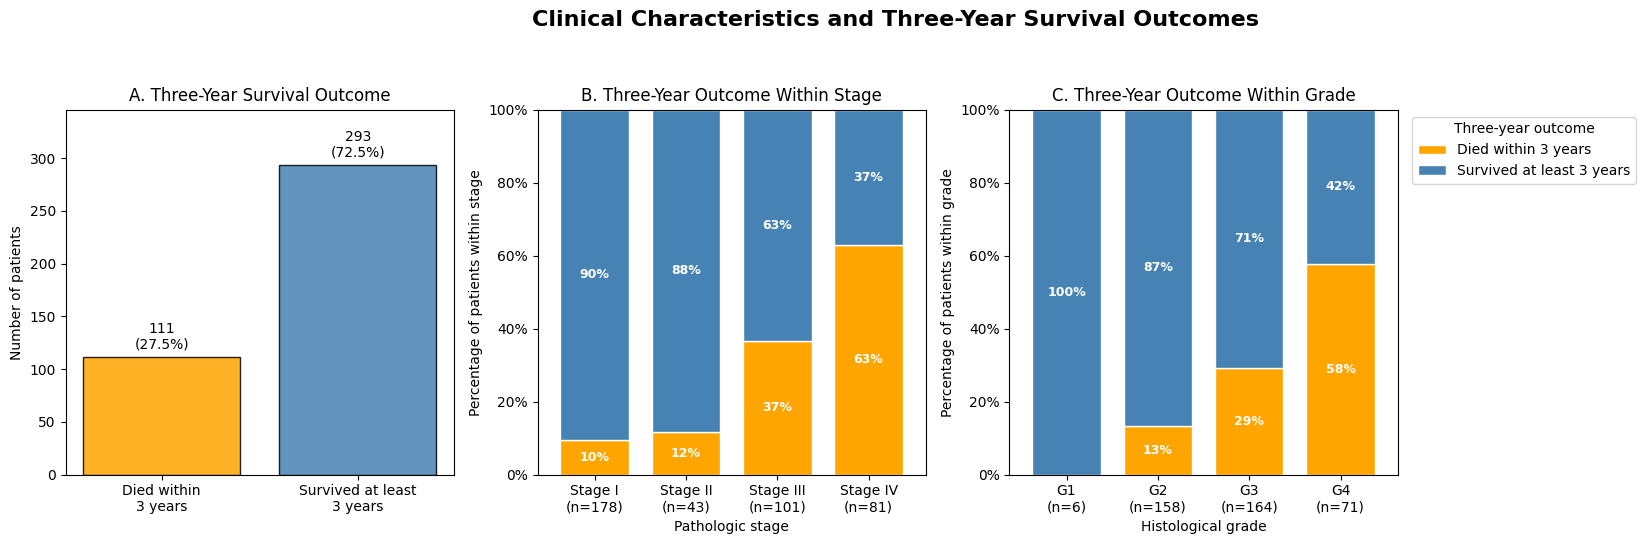

In [ ]:
# Create Figure 1

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Panel A: Overall outcome distribution

outcome_counts = (
    supervised["survival_3y"]
    .value_counts()
    .reindex([0, 1])
)

outcome_labels = [
    "Died within\n3 years",
    "Survived at least\n3 years"
]

bars = axes[0].bar(
    outcome_labels,
    outcome_counts.values,
    color=[
        outcome_colors["Died within 3 years"],
        outcome_colors["Survived at least 3 years"]
    ],
    edgecolor="black",
    alpha=0.85
)

axes[0].bar_label(
    bars,
    labels=[
        f"{count}\n({count / len(supervised):.1%})"
        for count in outcome_counts.values
    ],
    padding=4
)

axes[0].set_title(
    "A. Three-Year Survival Outcome"
)

axes[0].set_ylabel(
    "Number of patients"
)

axes[0].set_ylim(0, outcome_counts.max() * 1.18)


# Panel B: Outcome proportions within each stage

stage_proportions.plot(
    kind="bar",
    stacked=True,
    ax=axes[1],
    color=[
        outcome_colors["Died within 3 years"],
        outcome_colors["Survived at least 3 years"]
    ],
    edgecolor="white",
    width=0.75,
    legend=False
)

axes[1].set_title(
    "B. Three-Year Outcome Within Stage"
)

axes[1].set_xlabel(
    "Pathologic stage"
)

axes[1].set_ylabel(
    "Percentage of patients within stage"
)

axes[1].yaxis.set_major_formatter(
    PercentFormatter(xmax=1)
)

axes[1].set_ylim(0, 1)

axes[1].set_xticklabels(
    [
        f"{stage}\n(n={stage_counts.loc[stage].sum()})"
        for stage in stage_order
    ],
    rotation=0
)


# Add percentages inside stage bars
for container in axes[1].containers:

    labels = [
        f"{bar.get_height():.0%}"
        if bar.get_height() >= 0.05
        else ""
        for bar in container
    ]

    axes[1].bar_label(
        container,
        labels=labels,
        label_type="center",
        color="white",
        fontsize=9,
        fontweight="bold"
    )


# Panel C: Outcome proportions within each grade

grade_proportions.plot(
    kind="bar",
    stacked=True,
    ax=axes[2],
    color=[
        outcome_colors["Died within 3 years"],
        outcome_colors["Survived at least 3 years"]
    ],
    edgecolor="white",
    width=0.75
)

axes[2].set_title(
    "C. Three-Year Outcome Within Grade"
)

axes[2].set_xlabel(
    "Histological grade"
)

axes[2].set_ylabel(
    "Percentage of patients within grade"
)

axes[2].yaxis.set_major_formatter(
    PercentFormatter(xmax=1)
)

axes[2].set_ylim(0, 1)

axes[2].set_xticklabels(
    [
        f"{grade}\n(n={grade_counts.loc[grade].sum()})"
        for grade in grade_order
    ],
    rotation=0
)


# Add percentages inside grade bars
for container in axes[2].containers:

    labels = [
        f"{bar.get_height():.0%}"
        if bar.get_height() >= 0.05
        else ""
        for bar in container
    ]

    axes[2].bar_label(
        container,
        labels=labels,
        label_type="center",
        color="white",
        fontsize=9,
        fontweight="bold"
    )


# Move the legend outside Panel C
axes[2].legend(
    title="Three-year outcome",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)


# Overall figure title
fig.suptitle(
    "Clinical Characteristics and Three-Year Survival Outcomes",
    fontsize=16,
    fontweight="bold"
)


plt.tight_layout(
    rect=[0, 0, 0.92, 0.93]
)


# Save the figure
plt.savefig(
    FIGURE_DIR / "clinical_eda_three_panel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Stage I patients were mostly in the three-year survival group. In contrast, Stage IV had more patients who died within three years than patients who survived. This suggests that pathologic stage is likely an important clinical predictor.

Grades G2 and G3 were the most common groups. Death within three years became more common at higher grades, especially G4. Histological grade may therefore provide useful survival information.

Immune Cells Catagories: 22


,missing_count,missing_percent,zero_count,zero_percent,minimum,maximum,mean,median,std,unique_count
B.cells.naive,0,0.0,87,21.5347,0.0000,0.4731,0.0241,0.0131,0.0368,318
B.cells.memory,0,0.0,275,68.0693,0.0000,0.1730,0.0063,0.0000,0.0168,130
Plasma.cells,0,0.0,24,5.9406,0.0000,0.3167,0.0280,0.0175,0.0362,381
T.cells.CD8,0,0.0,3,0.7426,0.0000,0.5780,0.1944,0.1619,0.1228,402
T.cells.CD4.naive,0,0.0,398,98.5149,0.0000,0.1941,0.0008,0.0000,0.0102,7
T.cells.CD4.memory.resting,0,0.0,30,7.4257,0.0000,0.4195,0.1361,0.1352,0.0826,375
T.cells.CD4.memory.activated,0,0.0,371,91.8317,0.0000,0.0899,0.0013,0.0000,0.0070,34
T.cells.follicular.helper,0,0.0,52,12.8713,0.0000,0.1547,0.0345,0.0286,0.0311,353
T.cells.regulatory..Tregs.,0,0.0,69,17.0792,0.0000,0.1450,0.0277,0.0212,0.0271,336
T.cells.gamma.delta,0,0.0,343,84.9010,0.0000,0.0971,0.0031,0.0000,0.0106,62


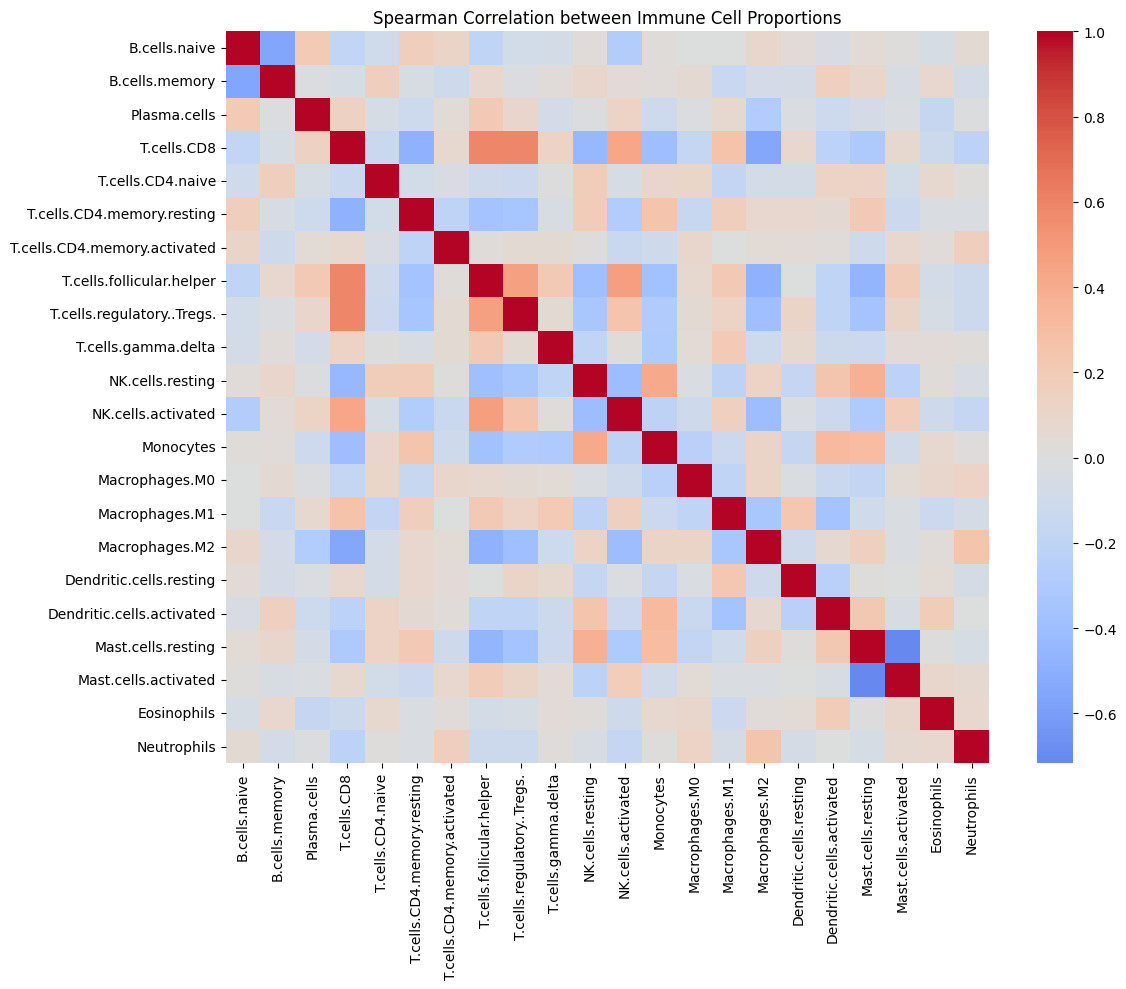

,B.cells.naive,B.cells.memory,Plasma.cells,T.cells.CD8,T.cells.CD4.naive,T.cells.CD4.memory.resting,T.cells.CD4.memory.activated,T.cells.follicular.helper,T.cells.regulatory..Tregs.,T.cells.gamma.delta,...,Monocytes,Macrophages.M0,Macrophages.M1,Macrophages.M2,Dendritic.cells.resting,Dendritic.cells.activated,Mast.cells.resting,Mast.cells.activated,Eosinophils,Neutrophils
B.cells.naive,1.000000,-0.556467,0.202348,-0.181793,-0.095882,0.174287,0.113202,-0.197121,-0.080757,-0.072561,...,0.015156,-0.002877,-0.002691,0.090639,0.034912,-0.035859,0.045216,0.009382,-0.049231,0.051117
B.cells.memory,-0.556467,1.000000,-0.014798,-0.047508,0.166494,-0.041231,-0.104699,0.083440,-0.012866,0.021959,...,0.033308,0.054943,-0.140422,-0.061768,-0.061723,0.160468,0.088070,-0.040604,0.082132,-0.075073
Plasma.cells,0.202348,-0.014798,1.000000,0.138388,-0.052605,-0.112259,0.046945,0.215018,0.096602,-0.060092,...,-0.111925,-0.017848,0.072462,-0.285219,-0.020586,-0.111080,-0.060870,-0.029721,-0.158073,-0.009650
T.cells.CD8,-0.181793,-0.047508,0.138388,1.000000,-0.135886,-0.485913,0.073559,0.586027,0.586267,0.131227,...,-0.399409,-0.160433,0.260986,-0.546969,0.082904,-0.223875,-0.303467,0.069126,-0.120579,-0.215912
T.cells.CD4.naive,-0.095882,0.166494,-0.052605,-0.135886,1.000000,-0.082776,-0.036573,-0.103862,-0.127957,0.001588,...,0.096276,0.106787,-0.176884,-0.079643,-0.079484,0.133624,0.128962,-0.081207,0.075578,0.009257
T.cells.CD4.memory.resting,0.174287,-0.041231,-0.112259,-0.485913,-0.082776,1.000000,-0.207209,-0.367281,-0.347566,-0.042497,...,0.250462,-0.153081,0.164127,0.087457,0.083802,0.058160,0.214756,-0.130599,-0.027065,-0.026094
T.cells.CD4.memory.activated,0.113202,-0.104699,0.046945,0.073559,-0.036573,-0.207209,1.000000,0.017463,0.053358,0.047966,...,-0.104136,0.093544,-0.000178,0.042490,0.037504,0.021230,-0.103990,0.084721,0.028430,0.172341
T.cells.follicular.helper,-0.197121,0.083440,0.215018,0.586027,-0.103862,-0.367281,0.017463,1.000000,0.462455,0.212856,...,-0.376344,0.069023,0.209662,-0.481396,-0.005678,-0.195540,-0.457859,0.192217,-0.073260,-0.123087
T.cells.regulatory..Tregs.,-0.080757,-0.012866,0.096602,0.586267,-0.127957,-0.347566,0.053358,0.462455,1.000000,0.048994,...,-0.292134,0.053471,0.129111,-0.390288,0.114135,-0.194278,-0.359514,0.111943,-0.049030,-0.122969
T.cells.gamma.delta,-0.072561,0.021959,-0.060092,0.131227,0.001588,-0.042497,0.047966,0.212856,0.048994,1.000000,...,-0.297649,0.043993,0.207838,-0.109783,0.076309,-0.117099,-0.132716,0.035644,0.038754,0.019867


In [ ]:
# check immune cells correlation
immune_features = ['B.cells.naive', 'B.cells.memory',
       'Plasma.cells', 'T.cells.CD8', 'T.cells.CD4.naive',
       'T.cells.CD4.memory.resting', 'T.cells.CD4.memory.activated',
       'T.cells.follicular.helper', 'T.cells.regulatory..Tregs.',
       'T.cells.gamma.delta', 'NK.cells.resting', 'NK.cells.activated',
       'Monocytes', 'Macrophages.M0', 'Macrophages.M1', 'Macrophages.M2',
       'Dendritic.cells.resting', 'Dendritic.cells.activated',
       'Mast.cells.resting', 'Mast.cells.activated', 'Eosinophils',
       'Neutrophils']

print(f"Immune Cells Catagories: {len(immune_features)}")

immune_data = supervised[immune_features].copy()

immune_quality_summary = pd.DataFrame({
    "missing_count": immune_data.isna().sum(),
    "missing_percent": immune_data.isna().mean() * 100,
    "zero_count": immune_data.eq(0).sum(),
    "zero_percent": (immune_data.eq(0).mean()) * 100,
    "minimum": immune_data.min(),
    "maximum": immune_data.max(),
    "mean": immune_data.mean(),
    "median": immune_data.median(),
    "std": immune_data.std(),
    "unique_count": immune_data.nunique(),
})

display(immune_quality_summary.round(4))

immune_quality_summary.to_csv(
    TABLE_DIR / "immune_cell_quality_summary.csv"
)

immune_correlation = immune_data.corr(method="spearman")

immune_correlation.to_csv(
    TABLE_DIR / "immune_cell_correlation.csv"
)

plt.figure(figsize=(12, 10))

sns.heatmap(immune_correlation, cmap="coolwarm", center=0)

plt.title("Spearman Correlation between Immune Cell Proportions")
plt.tight_layout()

plt.savefig(FIGURE_DIR / "immune_cell_correlation.png")

plt.show()

display(immune_correlation)




The 22 immune cell features had no missing values, but several features contained many zeros. The correlation heatmap also showed moderate or strong relationships between some immune cell proportions. These patterns may create multicollinearity and make dimension reduction useful.

,P.value,RMSE,Correlation
count,404.0000,404.0000,404.0000
mean,0.0589,1.0177,0.1901
std,0.1044,0.0425,0.0922
min,0.0000,0.7321,-0.0265
25%,0.0080,0.9962,0.1269
50%,0.0220,1.0202,0.1828
75%,0.0600,1.0456,0.2420
max,0.9320,1.1015,0.6835


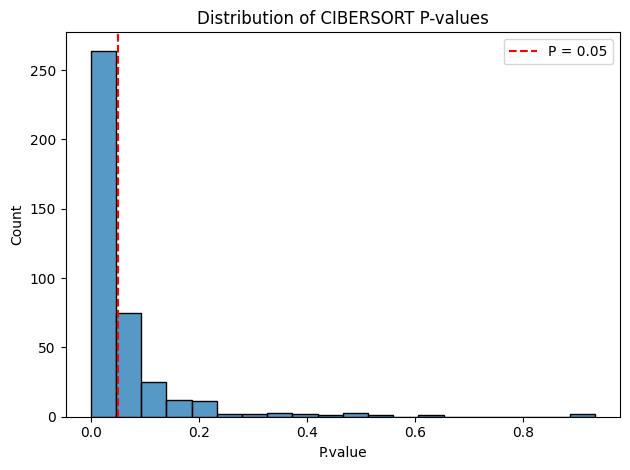

In [ ]:
# CIBERSORT quality plot

quality_cols = ["P.value", "RMSE", "Correlation"]
display(supervised[quality_cols].describe().round(4))

sns.histplot(
    data=supervised,
    x="P.value",
    bins=20
)

plt.axvline(
    0.05,
    color="red",
    linestyle="--",
    label="P = 0.05"
)

plt.legend()
plt.title("Distribution of CIBERSORT P-values")
plt.tight_layout()
plt.show()



The median CIBERSORT P-value was 0.022, but some patients had much higher values. Most estimates had relatively good quality, while a smaller group had weaker evidence. A sensitivity analysis using only patients with P-value at or below 0.05 may help test the robustness of the results.

,count
known_3y_outcome,
True,404
False,129


known_3y_outcome,False,True,All
ajcc_pathologic_tumor_stage,,,
Stage I,89,178,267
Stage II,14,43,57
Stage III,22,101,123
Stage IV,2,81,83
All,127,403,530


known_3y_outcome,False,True,All
histological_grade,,,
G1,8,6,14
G2,71,158,229
G3,42,164,206
G4,5,71,76
All,126,399,525


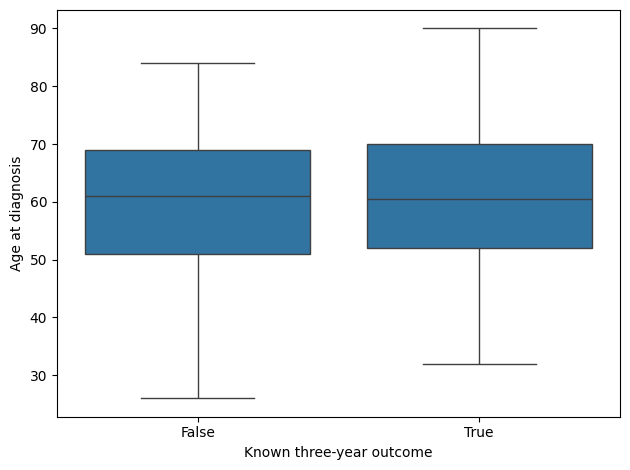

In [ ]:
# patients without 3 year followup

merged["known_3y_outcome"] = merged["survival_3y"].notna()
display(merged["known_3y_outcome"].value_counts())

display(pd.crosstab(
    merged["ajcc_pathologic_tumor_stage"],
    merged["known_3y_outcome"],
    margins=True
))

display(pd.crosstab(
    merged["histological_grade"],
    merged["known_3y_outcome"],
    margins=True
))

sns.boxplot(
    data=merged,
    x="known_3y_outcome",
    y="age_at_initial_pathologic_diagnosis"
)

plt.xlabel("Known three-year outcome")
plt.ylabel("Age at diagnosis")
plt.tight_layout()
plt.show()



The 129 patients with an unknown three-year outcome were not randomly distributed across stages. Many were Stage I patients, while very few were Stage IV patients. Their age distribution was similar to that of patients with known outcomes, but excluding them may still change the stage distribution of the supervised sample.

# **Part II: Supervised Learning**
## 2.1, System Setup

In [ ]:
import sklearn

from sklearn.base import clone

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import StratifiedKFold, GridSearchCV

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    ConfusionMatrixDisplay
)

from sklearn.utils.class_weight import compute_class_weight
from sklearn.inspection import permutation_importance

from sklearn.decomposition import PCA

RANDOM_STATE = 6


In [ ]:
# data check
assert supervised['patient_id'].is_unique, ('Some patients appear more than once.')
assert supervised['survival_3y'].notna().all(), ('survival_3y contains missing values.')
assert supervised['survival_3y'].isin([0, 1]).all(), ('survival_3y contains invalid values.')


In [ ]:
# check balanced class weights
# 0 = died within 3 years; 1 = survived at least 3 years
y = supervised["survival_3y"]

classes = np.array([0, 1])

balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y.to_numpy()
)

class_weight_summary = pd.DataFrame({
    "class": classes,

    "meaning": [
        "Death within 3 years",
        "Survived at least 3 years"
    ],

    "patient_count": [
        (y == 0).sum(),
        (y == 1).sum()
    ],

    "balanced_weight": balanced_weights
})

display(class_weight_summary.round(3))

,class,meaning,patient_count,balanced_weight
0,0,Death within 3 years,111,1.820
1,1,Survived at least 3 years,293,0.689


The supervised dataset contains more survivors than deaths. The calculated balanced weights were 1.820 for death and 0.689 for survival. Class weight was therefore included as a hyperparameter instead of being automatically applied to every model.

In [ ]:
# Setup features

clinical_numeric_features = ["age_at_initial_pathologic_diagnosis"]
clinical_categorical_features = [
    "gender",
    "ajcc_pathologic_tumor_stage",
    "histological_grade"
]

clinical_features = (clinical_numeric_features + clinical_categorical_features)

immune_features = [
    "B.cells.naive",
    "B.cells.memory",
    "Plasma.cells",
    "T.cells.CD8",
    "T.cells.CD4.naive",
    "T.cells.CD4.memory.resting",
    "T.cells.CD4.memory.activated",
    "T.cells.follicular.helper",
    "T.cells.regulatory..Tregs.",
    "T.cells.gamma.delta",
    "NK.cells.resting",
    "NK.cells.activated",
    "Monocytes",
    "Macrophages.M0",
    "Macrophages.M1",
    "Macrophages.M2",
    "Dendritic.cells.resting",
    "Dendritic.cells.activated",
    "Mast.cells.resting",
    "Mast.cells.activated",
    "Eosinophils",
    "Neutrophils"
]

combined_numeric_features = (clinical_numeric_features + immune_features)


In [ ]:
# Setup variables processing pipeline

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

immune_pca_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.90, svd_solver="full"))
])

In [ ]:
# Setup processor

clinical_preprocessor = ColumnTransformer([
    ("clinical_numeric", numeric_pipeline, clinical_numeric_features),
    ("clinical_categorical", categorical_pipeline, clinical_categorical_features)
])

combined_preprocessor = ColumnTransformer([
    ("combined_numeric", numeric_pipeline, combined_numeric_features),
    ("clinical_categorical", categorical_pipeline, clinical_categorical_features)
])

immune_preprocessor = ColumnTransformer([
    ("immune_numeric", numeric_pipeline, immune_features)
])

combined_pca_preprocessor = ColumnTransformer([
    ("clinical_numeric", numeric_pipeline, clinical_numeric_features),
    ("clinical_categorical", categorical_pipeline, clinical_categorical_features),
    ("immune_pca", immune_pca_pipeline, immune_features)
])

In [ ]:
# Setup model variables
X_clinical = supervised[clinical_features].copy()
X_immune = supervised[immune_features].copy()
X_combined = supervised[clinical_features + immune_features].copy()

y = supervised["survival_3y"].copy()

analysis_sets = {
    "Clinical only": {
        "X": X_clinical,
        "preprocessor": clinical_preprocessor
    },

    "Immune only": {
        "X": X_immune,
        "preprocessor": immune_preprocessor
    },

    "Clinical + immune": {
        "X": X_combined,
        "preprocessor": combined_preprocessor
    }
}

INCLUDE_PCA = True
if INCLUDE_PCA:
    analysis_sets[
        "Clinical + immune PCA"
    ] = {
        "X": X_combined,
        "preprocessor":
            combined_pca_preprocessor
    }

## 2.2, Three Models

In [ ]:
model_settings = {
    "Logistic Regression": {
        "model": LogisticRegression(
            solver="liblinear",
            penalty="l2",
            max_iter=3000,
            random_state=RANDOM_STATE
        ),
        "parameters": {
            "model__C": [0.1, 1, 10],
            "model__class_weight": [None, "balanced"]
        }
    },

    "SVM": {
        "model": SVC(),
        "parameters": {
            "model__C": [0.1, 1, 10],
            "model__kernel": [
                "linear",
                "rbf"
            ],
            "model__class_weight": [
                None,
                "balanced"
            ]
        }
    },

    "Random Forest": {
        "model": RandomForestClassifier(
            n_estimators=300,
            random_state=RANDOM_STATE,
            n_jobs=1
        ),
        "parameters": {
            "model__max_depth": [None, 5, 10],
            "model__min_samples_leaf": [1, 5],
            "model__class_weight": [
                None,
                "balanced"
            ]
        }
    }
}

Three model families were tested: Logistic Regression, Support Vector Machine, and Random Forest. These models represent linear, margin-based, and tree-based approaches. Their main hyperparameters and class-weight options were selected using inner cross-validation.

## 2.3, Cross Validation Training

In [ ]:
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# generate patient splits independently on clinical or immune features
# stratification is based only on the survival label y
# so each fold has similar ratio of death and survivor
outer_splits = list(outer_cv.split(np.zeros(len(y)), y))


In [ ]:
def get_prediction_score(fitted_pipeline, X):
    """
    Return prediction score.
    Higher score means a higher support for surviving at least 3 years.
    """
    # Logistic Regression and Random Forrest - probablity
    if hasattr(fitted_pipeline, "predict_proba"):
        return fitted_pipeline.predict_proba(X)[:, 1]

    # SVM - decision score
    return fitted_pipeline.decision_function(X)

In [ ]:
all_results = []
all_predictions = []
saved_models = {}

In [ ]:

for feature_set_name, analysis_info in analysis_sets.items():

    print("\n" + "=" * 70)
    print("FEATURE SET:", feature_set_name)
    print("=" * 70)

    X = analysis_info["X"]
    preprocessor = analysis_info["preprocessor"]

    for model_name, model_info in model_settings.items():

        print("\nMODEL:", model_name)

        model = model_info["model"]
        parameter_grid = model_info["parameters"]

        for fold, (train_index, test_index) in enumerate(outer_splits, start=1):

            # 1. Outer train/test split
            # the same patient indices are applied to each feature set
            X_train = X.iloc[train_index].copy()
            X_test = X.iloc[test_index].copy()

            y_train = y.iloc[train_index].copy()
            y_test = y.iloc[test_index].copy()

            # 2. Create inner CV
            inner_cv = StratifiedKFold(
                n_splits=3,
                shuffle=True,
                random_state=RANDOM_STATE
            )

            # 3. Complete modeling pipeline
            complete_pipeline = Pipeline([
                ("preprocess", clone(preprocessor)),
                ("model", clone(model))
            ])

            # 4. Hyperparameter search
            search = GridSearchCV(
                estimator=complete_pipeline,
                param_grid=parameter_grid,
                scoring="roc_auc",
                cv=inner_cv,
                n_jobs=-1,
                refit=True
            )

            # Only outer training data are used
            search.fit(X_train, y_train)

            # Best model selected by inner CV
            best_model = search.best_estimator_

            # Save RF which will be used later
            if (
                model_name == "Random Forest"
                and feature_set_name
                in ["Clinical only", "Clinical + immune"]
            ):
                saved_models[
                    (feature_set_name, fold)
                ] = best_model


            # 5. Predict outer test data
            predicted_class = best_model.predict(X_test)

            prediction_score = get_prediction_score(best_model, X_test)

            # Training score for overfitting check
            training_score = get_prediction_score(best_model, X_train)

            # 6. Calculate performance metrics
            roc_auc = roc_auc_score(y_test, prediction_score)
            pr_auc = average_precision_score(y_test, prediction_score)

            accuracy = accuracy_score(y_test, predicted_class)

            balanced_accuracy = (
                balanced_accuracy_score(
                    y_test,
                    predicted_class
                )
            )

            tn, fp, fn, tp = confusion_matrix(
                y_test,
                predicted_class,
                labels=[0, 1]
            ).ravel()

            # Survivor: survived at least 3 years
            survival_precision = precision_score(
                y_test,
                predicted_class,
                pos_label=1,
                zero_division=0
            )

            survival_recall = recall_score(
                y_test,
                predicted_class,
                pos_label=1,
                zero_division=0
            )

            survival_f1 = f1_score(
                y_test,
                predicted_class,
                pos_label=1,
                zero_division=0
            )

            # Death: died within 3 years
            death_precision = precision_score(
                y_test,
                predicted_class,
                pos_label=0,
                zero_division=0
            )

            death_recall = recall_score(
                y_test,
                predicted_class,
                pos_label=0,
                zero_division=0
            )

            death_f1 = f1_score(
                y_test,
                predicted_class,
                pos_label=0,
                zero_division=0
            )

            # Ability to correctly identify survivors
            survival_sensitivity = survival_recall

            # Ability to correctly identify deaths
            death_specificity = death_recall

            training_auc = roc_auc_score(y_train, training_score)

            overfitting_gap = training_auc - roc_auc

            selected_class_weight = search.best_params_["model__class_weight"]

            # 7. Set PCA
            pca_components = np.nan
            pca_explained_variance = np.nan
            if feature_set_name == "Clinical + immune PCA":
                fitted_pca = (
                    best_model
                    .named_steps["preprocess"]
                    .named_transformers_["immune_pca"]
                    .named_steps["pca"]
                )

                pca_components = fitted_pca.n_components_
                pca_explained_variance = (
                    fitted_pca.explained_variance_ratio_.sum()
                )

            # 8. Save fold results
            all_results.append({
                "feature_set": feature_set_name,
                "model": model_name,
                "outer_fold": fold,
                "roc_auc": roc_auc,
                "pr_auc": pr_auc,
                "accuracy": accuracy,
                "balanced_accuracy": balanced_accuracy,
                "survival_precision": survival_precision,
                "survival_recall": survival_recall,
                "survival_f1": survival_f1,
                "death_precision": death_precision,
                "death_recall": death_recall,
                "death_f1": death_f1,
                "survival_sensitivity": survival_sensitivity,
                "death_specificity": death_specificity,
                "training_auc": training_auc,
                "overfitting_gap": overfitting_gap,
                "selected_class_weight": str(selected_class_weight),
                "best_parameters": search.best_params_,
                "pca_components": pca_components,
                "pca_explained_variance": pca_explained_variance
            })

            # 9. Save patient predictions
            fold_predictions = pd.DataFrame({
                "patient_id":
                    supervised.iloc[test_index]["patient_id"].to_numpy(),
                "feature_set":
                    feature_set_name,
                "model":
                    model_name,
                "outer_fold":
                    fold,
                "actual_outcome":
                    y_test.to_numpy(),
                "predicted_class":
                    predicted_class,
                "prediction_score":
                    prediction_score
            })

            all_predictions.append(fold_predictions)

            print(
                f"Fold {fold}: "
                f"ROC-AUC={roc_auc:.3f}, "
                f"PR-AUC={pr_auc:.3f}, "
                f"Accuracy={accuracy:.3f}, "
                f"Balanced accuracy={balanced_accuracy:.3f},"
                f"Weight={selected_class_weight}"
            )


FEATURE SET: Clinical only

MODEL: Logistic Regression
Fold 1: ROC-AUC=0.833, PR-AUC=0.923, Accuracy=0.815, Balanced accuracy=0.702,Weight=None
Fold 2: ROC-AUC=0.767, PR-AUC=0.909, Accuracy=0.741, Balanced accuracy=0.580,Weight=None
Fold 3: ROC-AUC=0.834, PR-AUC=0.913, Accuracy=0.877, Balanced accuracy=0.787,Weight=None
Fold 4: ROC-AUC=0.755, PR-AUC=0.881, Accuracy=0.704, Balanced accuracy=0.714,Weight=balanced
Fold 5: ROC-AUC=0.743, PR-AUC=0.855, Accuracy=0.762, Balanced accuracy=0.752,Weight=balanced

MODEL: SVM
Fold 1: ROC-AUC=0.801, PR-AUC=0.851, Accuracy=0.778, Balanced accuracy=0.790,Weight=balanced
Fold 2: ROC-AUC=0.780, PR-AUC=0.917, Accuracy=0.679, Balanced accuracy=0.723,Weight=balanced
Fold 3: ROC-AUC=0.813, PR-AUC=0.889, Accuracy=0.716, Balanced accuracy=0.748,Weight=balanced
Fold 4: ROC-AUC=0.740, PR-AUC=0.866, Accuracy=0.667, Balanced accuracy=0.689,Weight=balanced
Fold 5: ROC-AUC=0.746, PR-AUC=0.872, Accuracy=0.700, Balanced accuracy=0.723,Weight=balanced

MODEL: Random

Five-fold nested cross-validation was used for evaluation. The same outer patient folds were used for every model and feature set, while three-fold inner cross-validation selected the hyperparameters. In total, the analysis produced 60 outer-fold results from three models and four feature sets.

## 2.4, Results

In [ ]:
results_df = pd.DataFrame(all_results)

predictions_df = pd.concat(all_predictions, ignore_index=True)

display(results_df.head())

,feature_set,model,outer_fold,roc_auc,pr_auc,accuracy,balanced_accuracy,survival_precision,survival_recall,survival_f1,...,death_recall,death_f1,survival_sensitivity,death_specificity,training_auc,overfitting_gap,selected_class_weight,best_parameters,pca_components,pca_explained_variance
0,Clinical only,Logistic Regression,1,0.833205,0.923056,0.814815,0.701849,0.823529,0.949153,0.881890,...,0.454545,0.571429,0.949153,0.454545,0.795160,-0.038045,None,"{'model__C': 1, 'model__class_weight': None}",NaN,NaN
1,Clinical only,Logistic Regression,2,0.767334,0.909421,0.740741,0.579738,0.763889,0.932203,0.839695,...,0.227273,0.322581,0.932203,0.227273,0.811798,0.044463,None,"{'model__C': 0.1, 'model__class_weight': None}",NaN,NaN
2,Clinical only,Logistic Regression,3,0.834361,0.912525,0.876543,0.786980,0.865672,0.983051,0.920635,...,0.590909,0.722222,0.983051,0.590909,0.798881,-0.035479,None,"{'model__C': 10, 'model__class_weight': None}",NaN,NaN
3,Clinical only,Logistic Regression,4,0.755247,0.881074,0.703704,0.714393,0.869565,0.689655,0.769231,...,0.739130,0.586207,0.689655,0.739130,0.819294,0.064047,balanced,"{'model__C': 1, 'model__class_weight': 'balanc...",NaN,NaN
4,Clinical only,Logistic Regression,5,0.742555,0.854792,0.762500,0.751567,0.882353,0.775862,0.825688,...,0.727273,0.627451,0.775862,0.727273,0.824791,0.082236,balanced,"{'model__C': 10, 'model__class_weight': 'balan...",NaN,NaN


In [ ]:
summary_table = (
    results_df
    .groupby(["model", "feature_set"])
    .agg(
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_sd=("roc_auc", "std"),
        pr_auc_mean=("pr_auc", "mean"),
        pr_auc_sd=("pr_auc", "std"),
        balanced_accuracy_mean=("balanced_accuracy", "mean"),
        balanced_accuracy_sd=("balanced_accuracy", "std"),
        survival_precision_mean=("survival_precision", "mean"),
        survival_precision_sd=("survival_precision", "std"),
        survival_recall_mean=("survival_recall", "mean"),
        survival_recall_sd=("survival_recall", "std"),
        survival_f1_mean=("survival_f1", "mean"),
        survival_f1_sd=("survival_f1", "std"),
        death_precision_mean=("death_precision", "mean"),
        death_precision_sd=("death_precision", "std"),
        death_recall_mean=("death_recall", "mean"),
        death_recall_sd=("death_recall", "std"),
        death_f1_mean=("death_f1", "mean"),
        death_f1_sd=("death_f1", "std"),
        survival_sensitivity_mean=("survival_sensitivity", "mean"),
        survival_sensitivity_sd=("survival_sensitivity", "std"),
        death_specificity_mean=("death_specificity", "mean"),
        death_specificity_sd=("death_specificity", "std"),
        training_auc_mean=("training_auc", "mean"),
        training_auc_sd=("training_auc", "std"),
        overfitting_gap_mean=("overfitting_gap", "mean"),
        overfitting_gap_sd=("overfitting_gap", "std"),
    )
    .reset_index()
    .round(3)
)

display(summary_table)

,model,feature_set,roc_auc_mean,roc_auc_sd,pr_auc_mean,pr_auc_sd,balanced_accuracy_mean,balanced_accuracy_sd,survival_precision_mean,survival_precision_sd,...,death_f1_mean,death_f1_sd,survival_sensitivity_mean,survival_sensitivity_sd,death_specificity_mean,death_specificity_sd,training_auc_mean,training_auc_sd,overfitting_gap_mean,overfitting_gap_sd
0,Logistic Regression,Clinical + immune,0.768,0.045,0.884,0.034,0.673,0.048,0.827,0.045,...,0.518,0.080,0.812,0.144,0.534,0.193,0.853,0.011,0.084,0.056
1,Logistic Regression,Clinical + immune PCA,0.773,0.043,0.891,0.031,0.659,0.033,0.814,0.035,...,0.492,0.057,0.839,0.108,0.479,0.169,0.848,0.011,0.075,0.053
2,Logistic Regression,Clinical only,0.787,0.044,0.896,0.028,0.707,0.079,0.841,0.048,...,0.566,0.148,0.866,0.127,0.548,0.213,0.810,0.013,0.023,0.057
3,Logistic Regression,Immune only,0.620,0.052,0.807,0.044,0.568,0.043,0.764,0.029,...,0.367,0.074,0.747,0.155,0.389,0.155,0.750,0.015,0.130,0.063
4,Random Forest,Clinical + immune,0.791,0.028,0.902,0.021,0.641,0.067,0.799,0.047,...,0.442,0.130,0.894,0.080,0.389,0.207,0.976,0.012,0.185,0.019
5,Random Forest,Clinical + immune PCA,0.800,0.013,0.907,0.018,0.709,0.039,0.835,0.024,...,0.578,0.062,0.877,0.046,0.541,0.086,0.986,0.008,0.186,0.014
6,Random Forest,Clinical only,0.805,0.048,0.909,0.026,0.719,0.054,0.854,0.040,...,0.587,0.074,0.806,0.059,0.632,0.118,0.875,0.015,0.070,0.062
7,Random Forest,Immune only,0.643,0.036,0.822,0.016,0.505,0.031,0.727,0.015,...,0.088,0.095,0.956,0.029,0.055,0.059,0.979,0.013,0.337,0.041
8,SVM,Clinical + immune,0.726,0.024,0.868,0.023,0.627,0.074,0.803,0.051,...,0.402,0.227,0.812,0.148,0.442,0.282,0.870,0.050,0.144,0.063
9,SVM,Clinical + immune PCA,0.743,0.011,0.876,0.017,0.618,0.080,0.789,0.048,...,0.399,0.189,0.866,0.090,0.369,0.225,0.865,0.047,0.122,0.054


The clinical-only Random Forest had the highest mean ROC-AUC at 0.805. The Random Forest with clinical and PCA immune features reached 0.800, while the model with raw clinical and immune features reached 0.791. The immune-only Random Forest had a lower ROC-AUC of 0.643.

The clinical-only SVM had the highest balanced accuracy at 0.734. This shows that the model with the best ROC-AUC was not necessarily the best at balancing the two outcome classes.

Overall, adding the immune variables did not improve the average ROC-AUC beyond the clinical-only models. PCA reduced some variation across folds, but it did not produce a higher average ROC-AUC than the clinical baseline.

In [ ]:
# Summarize the four feature representations for each model family.
family_results = (
    results_df
    .groupby(
        ["model", "feature_set"],
        as_index=False
    )
    .agg(
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_sd=("roc_auc", "std"),
        pr_auc_mean=("pr_auc", "mean"),
        pr_auc_sd=("pr_auc", "std"),
        balanced_accuracy_mean=(
            "balanced_accuracy", "mean"
        ),
        balanced_accuracy_sd=(
            "balanced_accuracy", "std"
        )
    )
)

# For each model family, select the feature representation with the highest mean ROC-AUC.
best_row_indices = (
    family_results
    .groupby("model")["roc_auc_mean"]
    .idxmax()
)

best_family_table = (
    family_results
    .loc[best_row_indices]
    .copy()
)

# Create readable "mean ± SD" columns.
best_family_table["ROC-AUC"] = (
    best_family_table.apply(
        lambda row:
            f"{row['roc_auc_mean']:.3f} "
            f"± {row['roc_auc_sd']:.3f}",
        axis=1
    )
)

best_family_table["Survival AP"] = (
    best_family_table.apply(
        lambda row:
            f"{row['pr_auc_mean']:.3f} "
            f"± {row['pr_auc_sd']:.3f}",
        axis=1
    )
)

best_family_table["Balanced accuracy"] = (
    best_family_table.apply(
        lambda row:
            f"{row['balanced_accuracy_mean']:.3f} "
            f"± {row['balanced_accuracy_sd']:.3f}",
        axis=1
    )
)

# Put model families in a meaningful order.
model_order = [
    "Logistic Regression",
    "SVM",
    "Random Forest"
]

best_family_table["model"] = pd.Categorical(
    best_family_table["model"],
    categories=model_order,
    ordered=True
)

best_family_table = (
    best_family_table
    .sort_values("model")
    [
        [
            "model",
            "feature_set",
            "ROC-AUC",
            "Survival AP",
            "Balanced accuracy"
        ]
    ]
    .rename(
        columns={
            "model": "Model family",
            "feature_set": "Best feature representation"
        }
    )
)

display(best_family_table)

,Model family,Best feature representation,ROC-AUC,Survival AP,Balanced accuracy
2,Logistic Regression,Clinical only,0.787 ± 0.044,0.896 ± 0.028,0.707 ± 0.079
10,SVM,Clinical only,0.776 ± 0.033,0.879 ± 0.025,0.734 ± 0.038
6,Random Forest,Clinical only,0.805 ± 0.048,0.909 ± 0.026,0.719 ± 0.054


,patient_id
feature_set,
Clinical + immune,404
Clinical only,404


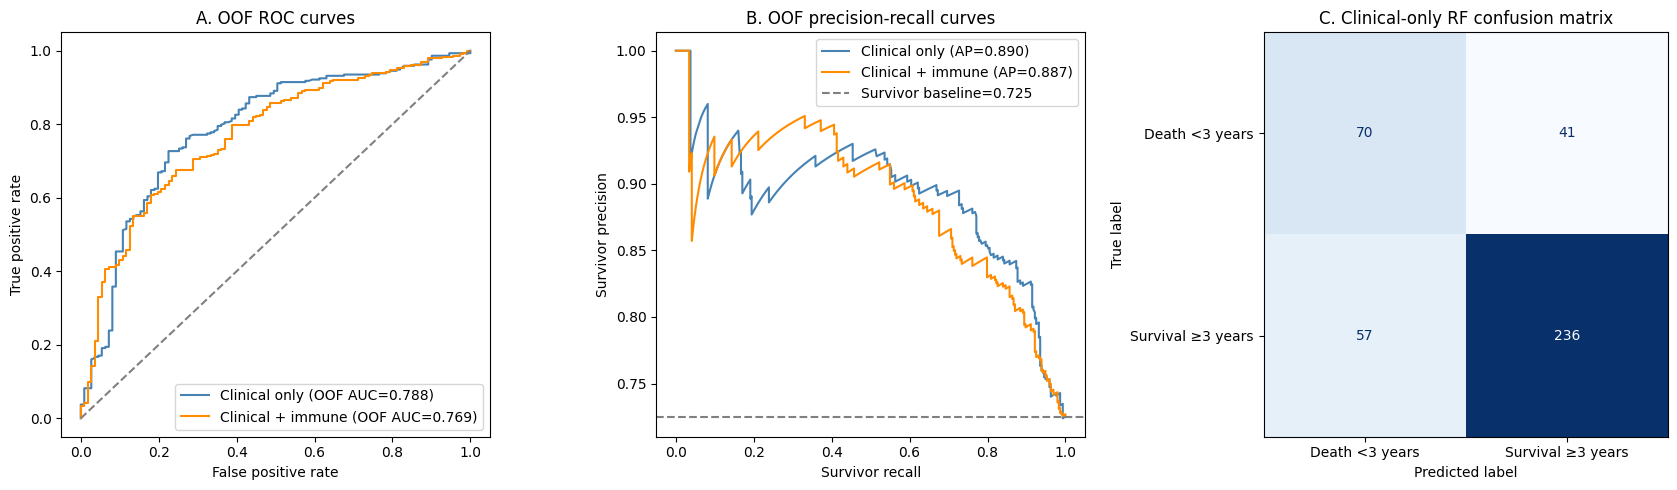

In [ ]:
# Evaluation plots

# Keep Random Forest predictions for the two feature sets that directly answer the main research question.
rf_plot_predictions = (
    predictions_df[
        (predictions_df["model"] == "Random Forest")
        &
        (
            predictions_df["feature_set"].isin(
                [
                    "Clinical only",
                    "Clinical + immune"
                ]
            )
        )
    ]
    .copy()
)

# Check that every feature set has one OOF prediction for each of the 404 patients.
prediction_counts = (
    rf_plot_predictions
    .groupby("feature_set")["patient_id"]
    .nunique()
)

display(prediction_counts)

assert prediction_counts.eq(
    len(supervised)
).all()

figure, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)

plot_colors = {
    "Clinical only": "steelblue",
    "Clinical + immune": "darkorange"
}

# Panel A: ROC curves
for feature_set_name in [
    "Clinical only",
    "Clinical + immune"
]:

    current_predictions = (
        rf_plot_predictions[
            rf_plot_predictions["feature_set"]
            == feature_set_name
        ]
    )

    current_y = (
        current_predictions["actual_outcome"]
        .to_numpy()
    )

    current_score = (
        current_predictions["prediction_score"]
        .to_numpy()
    )

    false_positive_rate, true_positive_rate, _ = (
        roc_curve(
            current_y,
            current_score
        )
    )

    pooled_auc = roc_auc_score(
        current_y,
        current_score
    )

    axes[0].plot(
        false_positive_rate,
        true_positive_rate,
        label=(
            f"{feature_set_name} "
            f"(OOF AUC={pooled_auc:.3f})"
        ),
        color=plot_colors[feature_set_name]
    )

axes[0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("A. OOF ROC curves")
axes[0].legend()


# Panel B: Precision-recall curves
for feature_set_name in [
    "Clinical only",
    "Clinical + immune"
]:

    current_predictions = (
        rf_plot_predictions[
            rf_plot_predictions["feature_set"]
            == feature_set_name
        ]
    )

    current_y = (
        current_predictions["actual_outcome"]
        .to_numpy()
    )

    current_score = (
        current_predictions["prediction_score"]
        .to_numpy()
    )

    precision, recall, _ = (
        precision_recall_curve(
            current_y,
            current_score
        )
    )

    average_precision = (
        average_precision_score(
            current_y,
            current_score
        )
    )

    axes[1].plot(
        recall,
        precision,
        label=(
            f"{feature_set_name} "
            f"(AP={average_precision:.3f})"
        ),
        color=plot_colors[feature_set_name]
    )

# Positive class is survival.
survivor_baseline = (
    rf_plot_predictions[
        rf_plot_predictions["feature_set"]
        == "Clinical only"
    ]["actual_outcome"]
    .mean()
)

axes[1].axhline(
    survivor_baseline,
    linestyle="--",
    color="gray",
    label=(
        f"Survivor baseline="
        f"{survivor_baseline:.3f}"
    )
)

axes[1].set_xlabel("Survivor recall")
axes[1].set_ylabel("Survivor precision")
axes[1].set_title("B. OOF precision-recall curves")
axes[1].legend()


# Panel C: Confusion matrix for the best model
rf_clinical_oof = (
    rf_plot_predictions[
        rf_plot_predictions["feature_set"]
        == "Clinical only"
    ]
    .copy()
)

ConfusionMatrixDisplay.from_predictions(
    rf_clinical_oof["actual_outcome"],
    rf_clinical_oof["predicted_class"],
    labels=[0, 1],
    display_labels=[
        "Death <3 years",
        "Survival ≥3 years"
    ],
    cmap="Blues",
    colorbar=False,
    ax=axes[2]
)

axes[2].set_title(
    "C. Clinical-only RF confusion matrix"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "rf_oof_evaluation_panels.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,threshold,survivor_precision,survivor_recall,death_precision,death_recall,balanced_accuracy
0,0.3,0.797,0.925,0.656,0.378,0.652
1,0.4,0.837,0.877,0.629,0.550,0.713
2,0.5,0.852,0.805,0.551,0.631,0.718
3,0.6,0.885,0.734,0.516,0.748,0.741
4,0.7,0.903,0.570,0.425,0.838,0.704


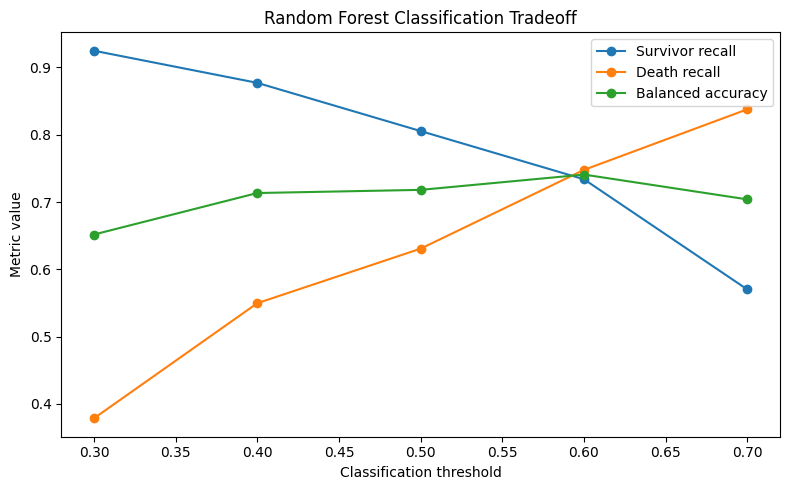

In [ ]:
# Evaluate different classification thresholds using the clinical-only Random Forest OOF scores.
threshold_rows = []

for threshold in [
    0.30,
    0.40,
    0.50,
    0.60,
    0.70
]:

    threshold_prediction = (
        rf_clinical_oof["prediction_score"]
        >= threshold
    ).astype(int)

    threshold_rows.append({
        "threshold": threshold,

        "survivor_precision":
            precision_score(
                rf_clinical_oof["actual_outcome"],
                threshold_prediction,
                pos_label=1,
                zero_division=0
            ),

        "survivor_recall":
            recall_score(
                rf_clinical_oof["actual_outcome"],
                threshold_prediction,
                pos_label=1,
                zero_division=0
            ),

        "death_precision":
            precision_score(
                rf_clinical_oof["actual_outcome"],
                threshold_prediction,
                pos_label=0,
                zero_division=0
            ),

        "death_recall":
            recall_score(
                rf_clinical_oof["actual_outcome"],
                threshold_prediction,
                pos_label=0,
                zero_division=0
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                rf_clinical_oof["actual_outcome"],
                threshold_prediction
            )
    })

threshold_table = pd.DataFrame(
    threshold_rows
)

display(
    threshold_table.round(3)
)

plt.figure(figsize=(8, 5))

plt.plot(
    threshold_table["threshold"],
    threshold_table["survivor_recall"],
    marker="o",
    label="Survivor recall"
)

plt.plot(
    threshold_table["threshold"],
    threshold_table["death_recall"],
    marker="o",
    label="Death recall"
)

plt.plot(
    threshold_table["threshold"],
    threshold_table["balanced_accuracy"],
    marker="o",
    label="Balanced accuracy"
)

plt.xlabel("Classification threshold")
plt.ylabel("Metric value")
plt.title(
    "Random Forest Classification Tradeoff"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "rf_threshold_tradeoff.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 2.5 Paired comparison

In [ ]:
# Clinical only
clinical_results = (
    results_df[
        results_df["feature_set"] == "Clinical only"
    ]
    [
        [
            "model",
            "outer_fold",
            "roc_auc",
            "pr_auc"
        ]
    ]
    .rename(
        columns={
            "roc_auc": "clinical_roc_auc",
            "pr_auc": "clinical_pr_auc"
        }
    )
)

# Clinical + Immune
combined_results = (
    results_df[
        results_df["feature_set"] == "Clinical + immune"
    ]
    [
        [
            "model",
            "outer_fold",
            "roc_auc",
            "pr_auc"
        ]
    ]
    .rename(
        columns={
            "roc_auc": "combined_roc_auc",
            "pr_auc": "combined_pr_auc"
        }
    )
)

paired_comparison = (
    clinical_results
    .merge(
        combined_results,
        on=["model", "outer_fold"],
        how="inner",
        validate="one_to_one"
    )
)

paired_comparison["roc_auc_change"] = (
    paired_comparison["combined_roc_auc"]
    - paired_comparison["clinical_roc_auc"]
)

paired_comparison["pr_auc_change"] = (
    paired_comparison["combined_pr_auc"]
    - paired_comparison["clinical_pr_auc"]
)

improvement_summary = (
    paired_comparison
    .groupby("model", as_index=False)
    .agg(
        roc_auc_change_mean=("roc_auc_change", "mean"),
        roc_auc_change_sd=("roc_auc_change", "std"),
        roc_auc_smallest_change=("roc_auc_change", "min"),
        roc_auc_largest_change=("roc_auc_change", "max"),
        roc_auc_folds_improved=("roc_auc_change",
            lambda x: int((x > 0).sum())
        ),
        pr_auc_change_mean=("pr_auc_change", "mean"),
        pr_auc_change_sd=("pr_auc_change", "std")
    )
)

display(improvement_summary.round(3))

,model,roc_auc_change_mean,roc_auc_change_sd,roc_auc_smallest_change,roc_auc_largest_change,roc_auc_folds_improved,pr_auc_change_mean,pr_auc_change_sd
0,Logistic Regression,-0.018,0.039,-0.083,0.012,2,-0.012,0.013
1,Random Forest,-0.014,0.023,-0.037,0.022,1,-0.007,0.012
2,SVM,-0.050,0.052,-0.094,0.021,1,-0.011,0.041


For Logistic Regression, adding the raw immune features changed ROC-AUC by an average of -0.018. The average changes were -0.014 for Random Forest and -0.050 for SVM. Improvement occurred in only two of five folds for Logistic Regression and one of five folds for both Random Forest and SVM.

The PR-AUC changes were also negative for all three models. These paired results do not show consistent improvement from adding the raw immune variables.

## 2.6, Overfitting Summary

In [ ]:
overfitting_summary = (
    results_df
    .groupby(
        ["model", "feature_set"],
        as_index=False
    )
    .agg(
        training_auc_mean=("training_auc", "mean"),
        test_auc_mean=("roc_auc", "mean"),
        mean_gap=("overfitting_gap", "mean"),
        sd_gap=("overfitting_gap", "std")
    )
)


display(overfitting_summary.round(3))

,model,feature_set,training_auc_mean,test_auc_mean,mean_gap,sd_gap
0,Logistic Regression,Clinical + immune,0.853,0.768,0.084,0.056
1,Logistic Regression,Clinical + immune PCA,0.848,0.773,0.075,0.053
2,Logistic Regression,Clinical only,0.810,0.787,0.023,0.057
3,Logistic Regression,Immune only,0.750,0.620,0.130,0.063
4,Random Forest,Clinical + immune,0.976,0.791,0.185,0.019
5,Random Forest,Clinical + immune PCA,0.986,0.800,0.186,0.014
6,Random Forest,Clinical only,0.875,0.805,0.070,0.062
7,Random Forest,Immune only,0.979,0.643,0.337,0.041
8,SVM,Clinical + immune,0.870,0.726,0.144,0.063
9,SVM,Clinical + immune PCA,0.865,0.743,0.122,0.054


The clinical-only Logistic Regression and SVM had small average train-test AUC gaps of 0.023 and 0.032. The clinical-only Random Forest had a larger but moderate gap of 0.070.

The Random Forest showed more overfitting after immune features were added. Its mean train-test gap was 0.185 with raw immune features and 0.186 with PCA immune features. The immune-only Random Forest had the largest gap at 0.337, suggesting that it learned patterns that did not generalize well to the outer test folds.

## 2.7, Feature importance analysis

Compare two Random Forest models:
1. Clinical-only, which is the best overall model.
2. Clinical + immune, which is included because it directly relates to the main research question.



In [ ]:
# Feature sets used for permutation importance.
IMPORTANCE_FEATURE_SETS = [
    "Clinical only",
    "Clinical + immune"
]

importance_rows = []

for feature_set_name in IMPORTANCE_FEATURE_SETS:

    print(
        "\nCalculating permutation importance for:",
        feature_set_name
    )

    # Select the correct original feature table.
    current_X = analysis_sets[
        feature_set_name
    ]["X"]

    # Use each saved outer-fold model.
    for fold in range(
        1,
        len(outer_splits) + 1
    ):

        # Recover the test patients from this outer fold.
        train_index, test_index = (
            outer_splits[fold - 1]
        )

        X_test = (
            current_X
            .iloc[test_index]
            .copy()
        )

        y_test = (
            y
            .iloc[test_index]
            .copy()
        )

        # Retrieve the model previously fitted in Section 2.3.
        model_key = (
            feature_set_name,
            fold
        )

        assert model_key in saved_models, (
            f"Saved model not found: {model_key}. "
            "Please rerun Section 2.3."
        )

        fitted_model = saved_models[model_key]

        # Shuffle each original feature 30 times.
        # A larger decrease in ROC-AUC means the feature
        # was more useful to the fitted model.
        permutation_result = permutation_importance(
            estimator=fitted_model,
            X=X_test,
            y=y_test,
            scoring="roc_auc",
            n_repeats=30,
            random_state=RANDOM_STATE + fold,
            n_jobs=-1
        )

        for feature, importance in zip(
            current_X.columns,
            permutation_result.importances_mean
        ):

            if feature in clinical_features:
                feature_group = "Clinical"
            else:
                feature_group = "Immune"

            importance_rows.append({
                "feature_set": feature_set_name,
                "outer_fold": fold,
                "feature": feature,
                "feature_group": feature_group,
                "importance": importance
            })

# One row represents one feature in one outer fold.
importance_df = pd.DataFrame(
    importance_rows
)

display(importance_df.head())

print(
    "Expected rows:",
    (
        len(clinical_features)
        + len(clinical_features)
        + len(immune_features)
    )
    * len(outer_splits)
)

print(
    "Actual rows:",
    len(importance_df)
)


Calculating permutation importance for: Clinical only

Calculating permutation importance for: Clinical + immune


,feature_set,outer_fold,feature,feature_group,importance
0,Clinical only,1,age_at_initial_pathologic_diagnosis,Clinical,0.043772
1,Clinical only,1,gender,Clinical,-0.009412
2,Clinical only,1,ajcc_pathologic_tumor_stage,Clinical,0.215691
3,Clinical only,1,histological_grade,Clinical,0.062250
4,Clinical only,2,age_at_initial_pathologic_diagnosis,Clinical,0.017283


Expected rows: 150
Actual rows: 150


The clinical-only Random Forest had a mean ROC-AUC of 0.805, a PR-AUC of 0.909, and a balanced accuracy of 0.719. After adding the immune features, these values decreased to 0.791, 0.902, and 0.641. Therefore, adding the raw immune cell proportions did not improve the average prediction performance.

In [ ]:
feature_importance_summary = (
    importance_df
    .groupby(
        [
            "feature_set",
            "feature",
            "feature_group"
        ],
        as_index=False
    )
    .agg(
        importance_mean=("importance", "mean"),
        importance_sd=("importance", "std"),
        positive_folds=("importance", lambda x: int((x > 0).sum()))
    )
)

feature_importance_summary = (
    feature_importance_summary
    .sort_values(
        [
            "feature_set",
            "importance_mean"
        ],
        ascending=[
            True,
            False
        ]
    )
)

display(feature_importance_summary.round(3))

,feature_set,feature,feature_group,importance_mean,importance_sd,positive_folds
23,Clinical + immune,ajcc_pathologic_tumor_stage,Clinical,0.148,0.017,5
25,Clinical + immune,histological_grade,Clinical,0.035,0.012,5
0,Clinical + immune,B.cells.memory,Immune,0.010,0.008,4
22,Clinical + immune,age_at_initial_pathologic_diagnosis,Clinical,0.006,0.009,4
9,Clinical + immune,Mast.cells.resting,Immune,0.006,0.004,5
10,Clinical + immune,Monocytes,Immune,0.005,0.005,4
14,Clinical + immune,Plasma.cells,Immune,0.004,0.006,4
1,Clinical + immune,B.cells.naive,Immune,0.003,0.002,5
18,Clinical + immune,T.cells.CD8,Immune,0.002,0.004,3
21,Clinical + immune,T.cells.regulatory..Tregs.,Immune,0.002,0.006,3


In [ ]:
clinical_importance_comparison = (
    feature_importance_summary[
        feature_importance_summary["feature_group"] == "Clinical"
    ]
    .pivot(
        index="feature",
        columns="feature_set",
        values="importance_mean"
    )
    .reset_index()
)

display(clinical_importance_comparison.round(3))

feature_set,feature,Clinical + immune,Clinical only
0,age_at_initial_pathologic_diagnosis,0.006,0.028
1,ajcc_pathologic_tumor_stage,0.148,0.202
2,gender,0.000,0.005
3,histological_grade,0.035,0.043


In [ ]:
immune_importance_summary = (
    feature_importance_summary[
        (
            feature_importance_summary["feature_set"]
            == "Clinical + immune"
        )
        &
        (
            feature_importance_summary["feature_group"]
            == "Immune"
        )
    ]
    .sort_values(
        "importance_mean",
        ascending=False
    )
)

display(immune_importance_summary.head(10).round(3))

,feature_set,feature,feature_group,importance_mean,importance_sd,positive_folds
0,Clinical + immune,B.cells.memory,Immune,0.010,0.008,4
9,Clinical + immune,Mast.cells.resting,Immune,0.006,0.004,5
10,Clinical + immune,Monocytes,Immune,0.005,0.005,4
14,Clinical + immune,Plasma.cells,Immune,0.004,0.006,4
1,Clinical + immune,B.cells.naive,Immune,0.003,0.002,5
18,Clinical + immune,T.cells.CD8,Immune,0.002,0.004,3
21,Clinical + immune,T.cells.regulatory..Tregs.,Immune,0.002,0.006,3
15,Clinical + immune,T.cells.CD4.memory.activated,Immune,0.001,0.002,4
16,Clinical + immune,T.cells.CD4.memory.resting,Immune,0.001,0.006,3
5,Clinical + immune,Macrophages.M0,Immune,0.001,0.003,2


Pathologic stage was the most important predictor in both models. Its mean permutation importance was 0.203 in the clinical-only model and 0.144 in the clinical-plus-immune model. Histological grade and age also contributed to the clinical-only model, with mean importance values of 0.044 and 0.030. Gender had a much smaller importance of 0.007.

Among the immune variables, memory B cells had the highest mean importance at 0.011, followed by resting mast cells at 0.007. However, these values were much smaller than the importance of pathologic stage. Most other immune variables had importance values close to zero, and several had negative mean importance.

In [ ]:
def plot_feature_importance(
    feature_set_name,
    top_n=None,
    output_filename=None
):

    plot_data = (
        feature_importance_summary[
            feature_importance_summary["feature_set"]
            == feature_set_name
        ]
        .copy()
    )

    # For the combined model, show only the top features
    # so the plot is easier to read.
    if top_n is not None:
        plot_data = (
            plot_data
            .nlargest(
                top_n,
                "importance_mean"
            )
        )

    plot_data = (
        plot_data
        .sort_values("importance_mean")
    )

    colors = plot_data["feature_group"].map({
        "Clinical": "steelblue",
        "Immune": "darkorange"
    })

    plt.figure(
        figsize=(
            9,
            max(4, len(plot_data) * 0.35)
        )
    )

    plt.barh(
        plot_data["feature"],
        plot_data["importance_mean"],
        xerr=plot_data["importance_sd"],
        color=colors,
        capsize=3
    )

    plt.axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    plt.xlabel(
        "Mean decrease in outer-test ROC-AUC"
    )

    plt.ylabel("")

    plt.title(
        f"Permutation Importance: "
        f"{feature_set_name} Random Forest"
    )

    plt.tight_layout()

    if output_filename is not None:
        plt.savefig(
            FIGURE_DIR / output_filename,
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()

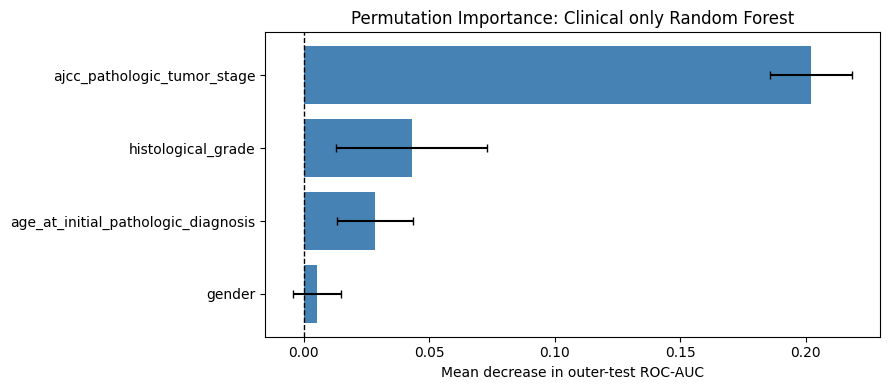

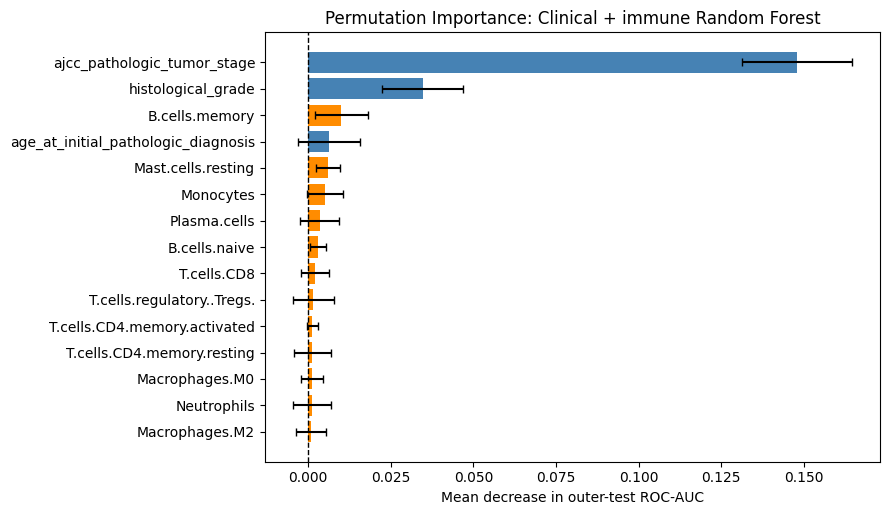

In [ ]:
# All four clinical variables
plot_feature_importance(
    feature_set_name="Clinical only",
    top_n=None,
    output_filename=(
        "clinical_only_rf_permutation_importance.png"
    )
)

# The 15 most important predictors in the combined model
plot_feature_importance(
    feature_set_name="Clinical + immune",
    top_n=15,
    output_filename=(
        "clinical_immune_rf_top15_permutation_importance.png"
    )
)

Overall, the Random Forest models mainly relied on clinical information, especially pathologic stage. A few immune features provided small predictive signals, but they did not improve the overall model performance. These importance values describe how the model used the variables for prediction; they should not be interpreted as biological or causal effects.

In [ ]:
importance_df.to_csv(
    TABLE_DIR / "permutation_importance_by_fold.csv",
    index=False
)

feature_importance_summary.to_csv(
    TABLE_DIR / "permutation_importance_summary.csv",
    index=False
)

print("Permutation importance results were saved.")

Permutation importance results were saved.


## 2.8, Block ablation

In [ ]:
ABLATION_MODEL_NAME = "Random Forest"

ABLATION_FEATURE_SETS = [
    "Clinical + immune",
    "Clinical only",
    "Immune only"
]

ABLATION_LABELS = {
    "Clinical + immune": "Full model",
    "Clinical only": "Remove immune block",
    "Immune only": "Remove clinical block"
}

ABLATION_METRICS = [
    "roc_auc",
    "pr_auc",
    "balanced_accuracy"
]

# These models were already trained in Section 2.3.
# They used the same outer folds and separate inner-fold tuning.
ablation_fold_results = (
    results_df[
        (results_df["model"] == ABLATION_MODEL_NAME)
        &
        (results_df["feature_set"].isin(ABLATION_FEATURE_SETS))
    ]
    [
        [
            "feature_set",
            "model",
            "outer_fold",
            "roc_auc",
            "pr_auc",
            "balanced_accuracy"
        ]
    ]
    .copy()
)

ablation_fold_results["analysis_label"] = (
    ablation_fold_results["feature_set"]
    .map(ABLATION_LABELS)
)

# Check that every feature set has five outer-fold results
assert not ablation_fold_results.duplicated(
    ["feature_set", "outer_fold"]
).any(), (
    "A feature set has more than one result for an outer fold."
)

fold_counts = (
    ablation_fold_results
    .groupby("feature_set")["outer_fold"]
    .nunique()
)

display(fold_counts)

assert fold_counts.eq(len(outer_splits)).all(), (
    "Some ablation models do not have all outer folds."
)

expected_rows = (
    len(ABLATION_FEATURE_SETS)
    * len(outer_splits)
)

assert len(ablation_fold_results) == expected_rows, (
    "The ablation result table has an unexpected number of rows."
)

print("Block ablation execution check passed.")

,outer_fold
feature_set,
Clinical + immune,5
Clinical only,5
Immune only,5


Block ablation execution check passed.


In [ ]:
# Summarize performance across the five outer folds
ablation_summary = (
    ablation_fold_results
    .groupby(
        [
            "feature_set",
            "analysis_label"
        ],
        as_index=False
    )
    .agg(
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_sd=("roc_auc", "std"),

        pr_auc_mean=("pr_auc", "mean"),
        pr_auc_sd=("pr_auc", "std"),

        balanced_accuracy_mean=("balanced_accuracy", "mean"),
        balanced_accuracy_sd=("balanced_accuracy", "std")
    )
)

# Keep the table in a meaningful order
display_order = {
    feature_set: order
    for order, feature_set
    in enumerate(ABLATION_FEATURE_SETS)
}

ablation_summary["display_order"] = (
    ablation_summary["feature_set"]
    .map(display_order)
)

ablation_summary = (
    ablation_summary
    .sort_values("display_order")
    .drop(columns="display_order")
    .reset_index(drop=True)
)

display(ablation_summary.round(3))

,feature_set,analysis_label,roc_auc_mean,roc_auc_sd,pr_auc_mean,pr_auc_sd,balanced_accuracy_mean,balanced_accuracy_sd
0,Clinical + immune,Full model,0.791,0.028,0.902,0.021,0.641,0.067
1,Clinical only,Remove immune block,0.805,0.048,0.909,0.026,0.719,0.054
2,Immune only,Remove clinical block,0.643,0.036,0.822,0.016,0.505,0.031


The full Random Forest model using clinical and immune features had a mean ROC-AUC of 0.791. After removing the immune features, ROC-AUC increased to 0.805, PR-AUC increased from 0.902 to 0.909, and balanced accuracy increased from 0.641 to 0.719. In contrast, removing the clinical features reduced ROC-AUC to 0.643, PR-AUC to 0.822, and balanced accuracy to 0.505.

In [ ]:
# Paired comparison with the full model

# Full-model results for each outer fold
full_fold_results = (
    ablation_fold_results[
        ablation_fold_results["feature_set"]
        == "Clinical + immune"
    ]
    [["outer_fold"] + ABLATION_METRICS]
    .rename(
        columns={
            metric: f"full_{metric}"
            for metric in ABLATION_METRICS
        }
    )
)

# Keep the two models that removed one feature block
ablation_change_by_fold = (
    ablation_fold_results[
        ablation_fold_results["feature_set"]
        != "Clinical + immune"
    ]
    .merge(
        full_fold_results,
        on="outer_fold",
        how="left",
        validate="many_to_one"
    )
)

removed_block_names = {
    "Clinical only": "Immune features",
    "Immune only": "Clinical features"
}

ablation_change_by_fold["removed_block"] = (
    ablation_change_by_fold["feature_set"]
    .map(removed_block_names)
)

# Change = ablated model - full model
# Positive value: performance improved after removing the block.
# Negative value: performance got worse after removing the block.
for metric in ABLATION_METRICS:

    ablation_change_by_fold[
        f"{metric}_change_after_removal"
    ] = (
        ablation_change_by_fold[metric]
        - ablation_change_by_fold[
            f"full_{metric}"
        ]
    )

display(
    ablation_change_by_fold[
        [
            "removed_block",
            "outer_fold",
            "roc_auc_change_after_removal",
            "pr_auc_change_after_removal",
            "balanced_accuracy_change_after_removal"
        ]
    ]
    .sort_values(
        ["removed_block", "outer_fold"]
    )
    .round(3)
)

,removed_block,outer_fold,roc_auc_change_after_removal,pr_auc_change_after_removal,balanced_accuracy_change_after_removal
5,Clinical features,1,-0.186,-0.101,-0.082
6,Clinical features,2,-0.086,-0.058,-0.168
7,Clinical features,3,-0.200,-0.106,-0.139
8,Clinical features,4,-0.096,-0.054,-0.066
9,Clinical features,5,-0.175,-0.080,-0.226
0,Immune features,1,0.037,0.024,0.171
1,Immune features,2,0.011,0.010,-0.048
2,Immune features,3,0.028,0.004,0.146
3,Immune features,4,-0.022,0.008,0.096
4,Immune features,5,0.015,-0.010,0.023


In [ ]:
# Summarize the paired changes across outer folds
REMOVAL_ORDER = ["Clinical only", "Immune only"]

change_summary_rows = []

for feature_set_name in REMOVAL_ORDER:

    current_results = (
        ablation_change_by_fold[
            ablation_change_by_fold["feature_set"]
            == feature_set_name
        ]
        .copy()
    )

    summary_row = {
        "removed_block":
            current_results["removed_block"].iloc[0],

        "remaining_feature_set":
            feature_set_name
    }

    for metric in ABLATION_METRICS:

        change_values = current_results[
            f"{metric}_change_after_removal"
        ]

        summary_row[
            f"{metric}_change_mean"
        ] = change_values.mean()

        summary_row[
            f"{metric}_change_sd"
        ] = change_values.std()

    roc_changes = current_results[
        "roc_auc_change_after_removal"
    ]

    summary_row["roc_auc_folds_improved"] = int(
        (roc_changes > 0).sum()
    )

    summary_row["roc_auc_folds_worsened"] = int(
        (roc_changes < 0).sum()
    )

    summary_row["roc_auc_folds_unchanged"] = int(
        (roc_changes == 0).sum()
    )

    change_summary_rows.append(summary_row)


ablation_change_summary = pd.DataFrame(
    change_summary_rows
)

display(ablation_change_summary.round(3))

,removed_block,remaining_feature_set,roc_auc_change_mean,roc_auc_change_sd,pr_auc_change_mean,pr_auc_change_sd,balanced_accuracy_change_mean,balanced_accuracy_change_sd,roc_auc_folds_improved,roc_auc_folds_worsened,roc_auc_folds_unchanged
0,Immune features,Clinical only,0.014,0.023,0.007,0.012,0.077,0.090,4,1,0
1,Clinical features,Immune only,-0.148,0.054,-0.080,0.024,-0.136,0.065,0,5,0


In the paired outer-fold comparison, removing the immune features changed ROC-AUC by an average of +0.014 and improved ROC-AUC in four of five folds. The changes were small and varied across folds. Removing the clinical features changed ROC-AUC by -0.148 and reduced ROC-AUC in all five folds. PR-AUC and balanced accuracy showed the same general pattern.

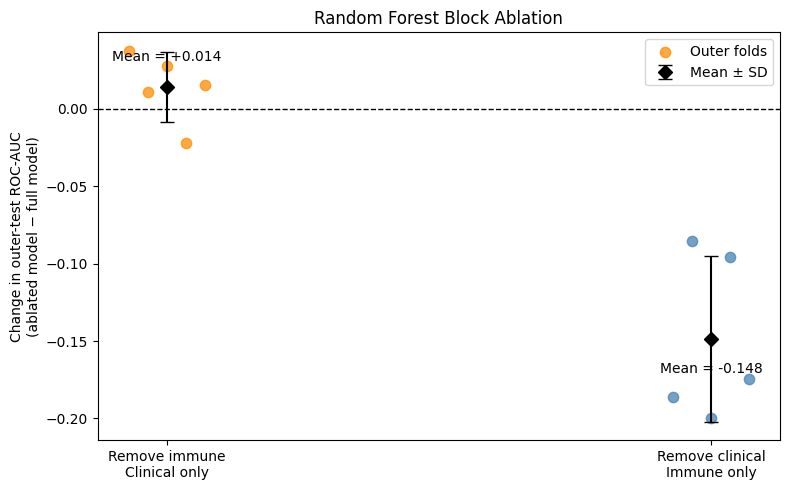

In [ ]:
# Plot the fold-level change in ROC-AUC

plot_labels = {
    "Clinical only":
        "Remove immune\nClinical only",

    "Immune only":
        "Remove clinical\nImmune only"
}

plot_colors = {
    "Clinical only": "darkorange",
    "Immune only": "steelblue"
}

fig, ax = plt.subplots(figsize=(8, 5))

for position, feature_set_name in enumerate(REMOVAL_ORDER):

    current_values = (
        ablation_change_by_fold[
            ablation_change_by_fold["feature_set"]
            == feature_set_name
        ]
        ["roc_auc_change_after_removal"]
        .to_numpy()
    )

    # Add a small horizontal separation, so the five fold points can be seen.
    horizontal_positions = (
        position
        + np.linspace(
            -0.07,
            0.07,
            len(current_values)
        )
    )

    ax.scatter(
        horizontal_positions,
        current_values,
        color=plot_colors[feature_set_name],
        alpha=0.75,
        s=55,
        label="Outer folds" if position == 0 else None
    )

    mean_change = current_values.mean()
    sd_change = current_values.std(ddof=1)

    # Diamond shows the mean.
    # Error bar shows one standard deviation.
    ax.errorbar(
        position,
        mean_change,
        yerr=sd_change,
        fmt="D",
        color="black",
        capsize=5,
        markersize=7,
        label="Mean ± SD" if position == 0 else None
    )

    text_offset = (
        0.015 if mean_change >= 0
        else -0.015
    )

    ax.text(
        position,
        mean_change + text_offset,
        f"Mean = {mean_change:+.3f}",
        ha="center",
        va=(
            "bottom"
            if mean_change >= 0
            else "top"
        )
    )


ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_xticks(
    range(len(REMOVAL_ORDER))
)

ax.set_xticklabels(
    [
        plot_labels[feature_set]
        for feature_set in REMOVAL_ORDER
    ]
)

ax.set_ylabel(
    "Change in outer-test ROC-AUC\n"
    "(ablated model − full model)"
)

ax.set_title(
    "Random Forest Block Ablation"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "rf_block_ablation_roc_auc_change.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Overall, the ablation results show that the clinical variables provided most of the predictive information. The immune feature block did not provide consistent additional value and may have added noise to the Random Forest model. This result does not mean that immune biology is unimportant. It only means that these CIBERSORT features did not improve three-year survival prediction in this dataset and modeling design.

In [ ]:
ablation_fold_results.to_csv(
    TABLE_DIR / "rf_block_ablation_by_fold.csv",
    index=False
)

ablation_summary.to_csv(
    TABLE_DIR / "rf_block_ablation_performance_summary.csv",
    index=False
)

ablation_change_by_fold.to_csv(
    TABLE_DIR / "rf_block_ablation_change_by_fold.csv",
    index=False
)

ablation_change_summary.to_csv(
    TABLE_DIR / "rf_block_ablation_change_summary.csv",
    index=False
)

print("Block ablation tables and figure were saved.")

Block ablation tables and figure were saved.


## 2.9, CIBERSORT quality sensitivity analysis

In [ ]:
CIBERSORT_P_THRESHOLD = 0.05

# Keep only patients with stronger CIBERSORT quality evidence
quality_data = (
    supervised[
        supervised["P.value"]
        <= CIBERSORT_P_THRESHOLD
    ]
    .copy()
    .reset_index(drop=True)
)

quality_y = quality_data["survival_3y"].copy()

print(
    f"Full supervised sample: {len(supervised)} \n",
    f"High-quality CIBERSORT sample: {len(quality_data)} \n"
)

print("\nClass counts:")
display(quality_y.value_counts())

# Five-fold stratified CV requires enough patients in both classes
assert quality_y.value_counts().min() >= 5, (
    "There are not enough patients in one class "
    "for five-fold cross-validation."
)

Full supervised sample: 404 
 High-quality CIBERSORT sample: 272 


Class counts:


,count
survival_3y,
1,194
0,78


In [ ]:
lower_quality_data = (
    supervised[
        supervised["P.value"]
        > CIBERSORT_P_THRESHOLD
    ]
    .copy()
)

quality_group_data = supervised.copy()

quality_group_data["quality_group"] = np.where(
    quality_group_data["P.value"]
    <= CIBERSORT_P_THRESHOLD,
    "P <= 0.05",
    "P > 0.05"
)

# Compare sample size, outcome, and age
quality_group_summary = (
    quality_group_data
    .groupby(
        "quality_group",
        as_index=False
    )
    .agg(
        patient_count=("patient_id", "size"),

        survivor_count=(
            "survival_3y",
            lambda values: int((values == 1).sum())
        ),

        death_count=(
            "survival_3y",
            lambda values: int((values == 0).sum())
        ),

        survival_rate=(
            "survival_3y",
            "mean"
        ),

        age_mean=(
            "age_at_initial_pathologic_diagnosis",
            "mean"
        ),

        age_sd=(
            "age_at_initial_pathologic_diagnosis",
            "std"
        )
    )
)

display(quality_group_summary.round(3))


,quality_group,patient_count,survivor_count,death_count,survival_rate,age_mean,age_sd
0,P <= 0.05,272,194,78,0.713,60.114,12.055
1,P > 0.05,132,99,33,0.750,62.326,11.851


In [ ]:
# Compare stage distributions
quality_group_data["stage_for_table"] = (
    quality_group_data[
        "ajcc_pathologic_tumor_stage"
    ]
    .astype("object")
    .fillna("Missing")
)

quality_stage_distribution = (
    pd.crosstab(
        quality_group_data["quality_group"],
        quality_group_data["stage_for_table"],
        normalize="index"
    )
    * 100
)

print("Stage distribution within each quality group (%):")
display(quality_stage_distribution.round(3))

Stage distribution within each quality group (%):


stage_for_table,Missing,Stage I,Stage II,Stage III,Stage IV
quality_group,,,,,
P <= 0.05,0.000,44.118,10.662,23.162,22.059
P > 0.05,0.758,43.939,10.606,28.788,15.909


Using the CIBERSORT P-value cutoff reduced the sample from 404 to 272 patients. The high-quality group included 194 survivors and 78 deaths, with a three-year survival rate of 71.3%. The lower-quality group had a survival rate of 75.0%. The age, stage, and grade distributions were generally similar, although the high-quality group included more Stage IV patients and fewer Stage III patients. Therefore, the quality filter produced a smaller and slightly different patient group.


In [ ]:
# Compare grade distributions
quality_group_data["grade_for_table"] = (
    quality_group_data["histological_grade"]
    .astype("object")
    .fillna("Missing")
)

quality_grade_distribution = (
    pd.crosstab(
        quality_group_data["quality_group"],
        quality_group_data["grade_for_table"],
        normalize="index"
    )
    * 100
)

print("Grade distribution within each quality group (%):")
display(quality_grade_distribution.round(3))

Grade distribution within each quality group (%):


grade_for_table,G1,G2,G3,G4,Missing
quality_group,,,,,
P <= 0.05,2.206,38.603,41.544,17.279,0.368
P > 0.05,0.000,40.152,38.636,18.182,3.030


In [ ]:
quality_analysis_sets = {
    "Clinical only": {
        "X": quality_data[clinical_features].copy(),
        "preprocessor": clinical_preprocessor
    },

    "Clinical + immune": {
        "X": quality_data[clinical_features + immune_features].copy(),
        "preprocessor": combined_preprocessor
    },

    "Clinical + immune PCA": {
        "X": quality_data[clinical_features + immune_features].copy(),
        "preprocessor": combined_pca_preprocessor
    }
}

quality_outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Use the same patient folds for all three quality-analysis sets
quality_outer_splits = list(
    quality_outer_cv.split(
        np.zeros(len(quality_y)),
        quality_y
    )
)

In [ ]:
# The report requires sensitivity analysis on the best-performing model.
QUALITY_MODEL_NAMES = ["Random Forest"]

quality_result_rows = []
quality_prediction_parts = []
quality_parameter_rows = []


for feature_set_name, analysis_info in (
    quality_analysis_sets.items()
):

    print("\n" + "=" * 70)
    print("QUALITY FEATURE SET:", feature_set_name)
    print("=" * 70)

    current_X = analysis_info["X"]
    current_preprocessor = analysis_info["preprocessor"]

    for model_name in QUALITY_MODEL_NAMES:

        print("\nMODEL:", model_name)

        model_template = (model_settings[model_name]["model"])

        parameter_grid = (model_settings[model_name]["parameters"])

        for fold, (train_index, test_index) in enumerate(
            quality_outer_splits,
            start=1
        ):

            # Split the high-quality patients
            X_train = current_X.iloc[train_index].copy()
            X_test = current_X.iloc[test_index].copy()

            y_train = quality_y.iloc[train_index].copy()
            y_test = quality_y.iloc[test_index].copy()

            # Hyperparameter tuning uses only the outer training data
            inner_cv = StratifiedKFold(
                n_splits=3,
                shuffle=True,
                random_state=RANDOM_STATE
            )

            pipeline = Pipeline([
                (
                    "preprocess",
                    clone(current_preprocessor)
                ),
                (
                    "model",
                    clone(model_template)
                )
            ])

            search = GridSearchCV(
                estimator=pipeline,
                param_grid=parameter_grid,
                scoring="roc_auc",
                cv=inner_cv,
                n_jobs=-1,
                refit=True
            )

            search.fit(X_train, y_train)

            best_model = search.best_estimator_


            # Outer-test predictions
            predicted_class = best_model.predict(
                X_test
            )

            prediction_score = get_prediction_score(
                best_model,
                X_test
            )


            # Performance measures
            roc_auc = roc_auc_score(
                y_test,
                prediction_score
            )

            pr_auc = average_precision_score(
                y_test,
                prediction_score
            )

            balanced_accuracy = (
                balanced_accuracy_score(
                    y_test,
                    predicted_class
                )
            )

            survival_sensitivity = recall_score(
                y_test,
                predicted_class,
                pos_label=1,
                zero_division=0
            )

            death_specificity = recall_score(
                y_test,
                predicted_class,
                pos_label=0,
                zero_division=0
            )


            # Save PCA information when PCA is used
            pca_components = np.nan
            pca_explained_variance = np.nan

            if (
                feature_set_name
                == "Clinical + immune PCA"
            ):

                fitted_pca = (
                    best_model
                    .named_steps["preprocess"]
                    .named_transformers_["immune_pca"]
                    .named_steps["pca"]
                )

                pca_components = (
                    fitted_pca.n_components_
                )

                pca_explained_variance = (
                    fitted_pca
                    .explained_variance_ratio_
                    .sum()
                )


            # Save one row for this outer fold
            quality_result_rows.append({
                "feature_set": feature_set_name,
                "model": model_name,
                "outer_fold": fold,
                "roc_auc": roc_auc,
                "pr_auc": pr_auc,
                "balanced_accuracy":
                    balanced_accuracy,
                "survival_sensitivity":
                    survival_sensitivity,
                "death_specificity":
                    death_specificity,
                "selected_class_weight": str(
                    search.best_params_.get(
                        "model__class_weight"
                    )
                ),
                "pca_components":
                    pca_components,
                "pca_explained_variance":
                    pca_explained_variance
            })


            # Save selected parameters
            quality_parameter_rows.append({
                "feature_set": feature_set_name,
                "model": model_name,
                "outer_fold": fold,
                "best_parameters":
                    search.best_params_
            })


            # Save one outer-test prediction
            # for each patient
            fold_predictions = pd.DataFrame({
                "patient_id":
                    quality_data.iloc[
                        test_index
                    ]["patient_id"].to_numpy(),

                "feature_set":
                    feature_set_name,

                "model":
                    model_name,

                "outer_fold":
                    fold,

                "actual_outcome":
                    y_test.to_numpy(),

                "predicted_class":
                    predicted_class,

                "prediction_score":
                    prediction_score
            })

            quality_prediction_parts.append(
                fold_predictions
            )

            print(
                f"Fold {fold}: "
                f"ROC-AUC={roc_auc:.3f}, "
                f"PR-AUC={pr_auc:.3f}, "
                f"Balanced accuracy="
                f"{balanced_accuracy:.3f}"
            )


QUALITY FEATURE SET: Clinical only

MODEL: Random Forest
Fold 1: ROC-AUC=0.872, PR-AUC=0.945, Balanced accuracy=0.805
Fold 2: ROC-AUC=0.722, PR-AUC=0.836, Balanced accuracy=0.659
Fold 3: ROC-AUC=0.809, PR-AUC=0.925, Balanced accuracy=0.736
Fold 4: ROC-AUC=0.898, PR-AUC=0.956, Balanced accuracy=0.774
Fold 5: ROC-AUC=0.858, PR-AUC=0.942, Balanced accuracy=0.747

QUALITY FEATURE SET: Clinical + immune

MODEL: Random Forest
Fold 1: ROC-AUC=0.837, PR-AUC=0.926, Balanced accuracy=0.688
Fold 2: ROC-AUC=0.750, PR-AUC=0.857, Balanced accuracy=0.693
Fold 3: ROC-AUC=0.749, PR-AUC=0.868, Balanced accuracy=0.749
Fold 4: ROC-AUC=0.863, PR-AUC=0.925, Balanced accuracy=0.736
Fold 5: ROC-AUC=0.796, PR-AUC=0.900, Balanced accuracy=0.679

QUALITY FEATURE SET: Clinical + immune PCA

MODEL: Random Forest
Fold 1: ROC-AUC=0.857, PR-AUC=0.926, Balanced accuracy=0.693
Fold 2: ROC-AUC=0.761, PR-AUC=0.852, Balanced accuracy=0.712
Fold 3: ROC-AUC=0.711, PR-AUC=0.846, Balanced accuracy=0.669
Fold 4: ROC-AUC=0.882

In [ ]:
# Convert saved results to DataFrames
quality_results_df = pd.DataFrame(quality_result_rows)

quality_parameters_df = pd.DataFrame(quality_parameter_rows)

quality_oof_predictions = pd.concat(
    quality_prediction_parts,
    ignore_index=True
)


# Check the expected number of fold results
expected_result_rows = (
    len(quality_analysis_sets)
    * len(QUALITY_MODEL_NAMES)
    * len(quality_outer_splits)
)

assert len(quality_results_df) == expected_result_rows, (
    "The number of quality-analysis results is incorrect."
)

assert not quality_results_df.duplicated(
    [
        "feature_set",
        "model",
        "outer_fold"
    ]
).any(), (
    "Some models have more than one result for an outer fold."
)


# Every patient should have one prediction for each model and feature set
quality_patient_counts = (
    quality_oof_predictions
    .groupby(
        ["feature_set", "model"]
    )
    .agg(
        total_rows=("patient_id", "size"),
        unique_patients=(
            "patient_id",
            "nunique"
        )
    )
)

display(quality_patient_counts)

assert (
    quality_patient_counts["total_rows"]
    == len(quality_data)
).all(), (
    "Some model contains an incorrect number of predictions."
)

assert (
    quality_patient_counts["unique_patients"]
    == len(quality_data)
).all(), (
    "Some patients are missing."
)

assert not quality_oof_predictions.duplicated(
    [
        "feature_set",
        "model",
        "patient_id"
    ]
).any(), (
    "Some patients have more than one outer-fold prediction."
)

print("Quality sensitivity execution check passed.")

,,total_rows,unique_patients
feature_set,model,,
Clinical + immune,Random Forest,272,272
Clinical + immune PCA,Random Forest,272,272
Clinical only,Random Forest,272,272


Quality sensitivity execution check passed.


In [ ]:
quality_performance_summary = (
    quality_results_df
    .groupby(
        ["model", "feature_set"],
        as_index=False
    )
    .agg(
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_sd=("roc_auc", "std"),

        pr_auc_mean=("pr_auc", "mean"),
        pr_auc_sd=("pr_auc", "std"),

        balanced_accuracy_mean=(
            "balanced_accuracy",
            "mean"
        ),
        balanced_accuracy_sd=(
            "balanced_accuracy",
            "std"
        ),

        survival_sensitivity_mean=(
            "survival_sensitivity",
            "mean"
        ),

        death_specificity_mean=(
            "death_specificity",
            "mean"
        )
    )
)

display(quality_performance_summary.round(3))

,model,feature_set,roc_auc_mean,roc_auc_sd,pr_auc_mean,pr_auc_sd,balanced_accuracy_mean,balanced_accuracy_sd,survival_sensitivity_mean,death_specificity_mean
0,Random Forest,Clinical + immune,0.799,0.051,0.896,0.032,0.709,0.031,0.928,0.490
1,Random Forest,Clinical + immune PCA,0.809,0.071,0.896,0.043,0.716,0.040,0.907,0.526
2,Random Forest,Clinical only,0.832,0.069,0.921,0.049,0.744,0.055,0.861,0.628


In the high-quality CIBERSORT subset, the clinical-only Random Forest achieved the highest mean ROC-AUC. Adding the raw immune features reduced the mean ROC-AUC, while PCA improved performance relative to the raw immune representation but remained below the clinical-only model. Therefore, restricting the analysis to stronger CIBERSORT results did not reverse the main conclusion.

In the high-quality subset, adding the raw immune features changed the Random Forest ROC-AUC by an average of −0.033 and improved ROC-AUC in only one of five outer folds. The sample size was also reduced from 404 to 272 patients. Therefore, the sensitivity analysis did not provide evidence that stricter CIBERSORT quality filtering improved the incremental value of the immune features.

In [ ]:
# Paired comparisons within the high-quality sample

QUALITY_COMPARISON_SETS = [
    "Clinical + immune",
    "Clinical + immune PCA"
]

quality_clinical_results = (
    quality_results_df[
        quality_results_df["feature_set"]
        == "Clinical only"
    ]
    [
        [
            "model",
            "outer_fold",
            "roc_auc",
            "pr_auc",
            "balanced_accuracy"
        ]
    ]
    .rename(
        columns={
            "roc_auc":
                "clinical_roc_auc",

            "pr_auc":
                "clinical_pr_auc",

            "balanced_accuracy":
                "clinical_balanced_accuracy"
        }
    )
)

quality_comparison_parts = []


for comparison_feature_set in (QUALITY_COMPARISON_SETS):

    comparison_results = (
        quality_results_df[
            quality_results_df["feature_set"]
            == comparison_feature_set
        ]
        [
            [
                "model",
                "outer_fold",
                "roc_auc",
                "pr_auc",
                "balanced_accuracy"
            ]
        ]
        .rename(
            columns={
                "roc_auc":
                    "comparison_roc_auc",

                "pr_auc":
                    "comparison_pr_auc",

                "balanced_accuracy":
                    "comparison_balanced_accuracy"
            }
        )
    )

    current_comparison = (
        quality_clinical_results
        .merge(
            comparison_results,
            on=[
                "model",
                "outer_fold"
            ],
            how="inner",
            validate="one_to_one"
        )
    )

    current_comparison[
        "comparison_feature_set"
    ] = comparison_feature_set

    current_comparison[
        "roc_auc_change"
    ] = (
        current_comparison["comparison_roc_auc"]
        - current_comparison["clinical_roc_auc"]
    )

    current_comparison[
        "pr_auc_change"
    ] = (current_comparison["comparison_pr_auc"]
        - current_comparison["clinical_pr_auc"]
    )

    current_comparison[
        "balanced_accuracy_change"
    ] = (
        current_comparison["comparison_balanced_accuracy"]
        - current_comparison["clinical_balanced_accuracy"]
    )

    quality_comparison_parts.append(current_comparison)


quality_paired_comparison = pd.concat(
    quality_comparison_parts,
    ignore_index=True
)


quality_improvement_summary = (
    quality_paired_comparison
    .groupby(
        [
            "model",
            "comparison_feature_set"
        ],
        as_index=False
    )
    .agg(
        roc_auc_change_mean=(
            "roc_auc_change",
            "mean"
        ),

        roc_auc_change_sd=(
            "roc_auc_change",
            "std"
        ),

        roc_auc_folds_improved=(
            "roc_auc_change",
            lambda values: int(
                (values > 0).sum()
            )
        ),

        pr_auc_change_mean=(
            "pr_auc_change",
            "mean"
        ),

        pr_auc_change_sd=(
            "pr_auc_change",
            "std"
        ),

        balanced_accuracy_change_mean=(
            "balanced_accuracy_change",
            "mean"
        ),

        balanced_accuracy_change_sd=(
            "balanced_accuracy_change",
            "std"
        )
    )
)

display(quality_improvement_summary.round(3))

,model,comparison_feature_set,roc_auc_change_mean,roc_auc_change_sd,roc_auc_folds_improved,pr_auc_change_mean,pr_auc_change_sd,balanced_accuracy_change_mean,balanced_accuracy_change_sd
0,Random Forest,Clinical + immune,-0.033,0.036,1,-0.025,0.030,-0.035,0.061
1,Random Forest,Clinical + immune PCA,-0.022,0.049,1,-0.025,0.034,-0.028,0.063


In [ ]:
# Full sample versus high-quality subset

FULL_COMPARISON_METRICS = [
    "roc_auc",
    "pr_auc",
    "balanced_accuracy"
]


# Recreate the full-sample paired comparison
full_clinical_results = (
    results_df[
        (results_df["feature_set"]== "Clinical only")
        &
        (results_df["model"].isin(QUALITY_MODEL_NAMES))
    ]
    [
        [
            "model",
            "outer_fold"
        ]
        + FULL_COMPARISON_METRICS
    ]
    .rename(
        columns={
            metric: f"clinical_{metric}"
            for metric
            in FULL_COMPARISON_METRICS
        }
    )
)

full_combined_results = (
    results_df[
        (results_df["feature_set"]== "Clinical + immune")
        &
        (results_df["model"].isin(QUALITY_MODEL_NAMES))
    ]
    [
        [
            "model",
            "outer_fold"
        ]
        + FULL_COMPARISON_METRICS
    ]
    .rename(
        columns={
            metric: f"combined_{metric}"
            for metric
            in FULL_COMPARISON_METRICS
        }
    )
)

full_sample_pairs = (
    full_clinical_results
    .merge(
        full_combined_results,
        on=["model", "outer_fold"],
        how="inner",
        validate="one_to_one"
    )
)


for metric in FULL_COMPARISON_METRICS:

    full_sample_pairs[
        f"{metric}_change"
    ] = (
        full_sample_pairs[f"combined_{metric}"]
        - full_sample_pairs[f"clinical_{metric}"]
    )


full_sample_change_summary = (
    full_sample_pairs
    .groupby(
        "model",
        as_index=False
    )
    .agg(
        full_roc_auc_change_mean=(
            "roc_auc_change",
            "mean"
        ),

        full_roc_auc_change_sd=(
            "roc_auc_change",
            "std"
        ),

        full_pr_auc_change_mean=(
            "pr_auc_change",
            "mean"
        ),

        full_balanced_accuracy_change_mean=(
            "balanced_accuracy_change",
            "mean"
        )
    )
)


# Keep only the raw immune comparison from the high-quality analysis
quality_raw_pairs = (
    quality_paired_comparison[
        quality_paired_comparison[
            "comparison_feature_set"
        ]
        == "Clinical + immune"
    ]
    .copy()
)

quality_raw_change_summary = (
    quality_raw_pairs
    .groupby(
        "model",
        as_index=False
    )
    .agg(
        quality_roc_auc_change_mean=(
            "roc_auc_change",
            "mean"
        ),

        quality_roc_auc_change_sd=(
            "roc_auc_change",
            "std"
        ),

        quality_pr_auc_change_mean=(
            "pr_auc_change",
            "mean"
        ),

        quality_balanced_accuracy_change_mean=(
            "balanced_accuracy_change",
            "mean"
        )
    )
)


sensitivity_change_comparison = (
    full_sample_change_summary
    .merge(
        quality_raw_change_summary,
        on="model",
        how="inner",
        validate="one_to_one"
    )
)

sensitivity_change_comparison[
    "roc_auc_change_difference"
] = (
    sensitivity_change_comparison[
        "quality_roc_auc_change_mean"
    ]
    - sensitivity_change_comparison[
        "full_roc_auc_change_mean"
    ]
)

sensitivity_change_comparison[
    "full_sample_n"
] = len(supervised)

sensitivity_change_comparison[
    "quality_sample_n"
] = len(quality_data)

display(sensitivity_change_comparison.round(3))

,model,full_roc_auc_change_mean,full_roc_auc_change_sd,full_pr_auc_change_mean,full_balanced_accuracy_change_mean,quality_roc_auc_change_mean,quality_roc_auc_change_sd,quality_pr_auc_change_mean,quality_balanced_accuracy_change_mean,roc_auc_change_difference,full_sample_n,quality_sample_n
0,Random Forest,-0.014,0.023,-0.007,-0.077,-0.033,0.036,-0.025,-0.035,-0.019,404,272


In the paired comparison, adding raw immune features changed ROC-AUC by −0.065 for Logistic Regression, −0.033 for Random Forest, and −0.077 for SVM. Logistic Regression and SVM did not improve in any outer fold, while Random Forest improved in only one of five folds. The PCA changes also remained negative. These negative changes were larger than those in the full sample, so restricting the analysis to stronger CIBERSORT results did not reverse the main conclusion. However, the sensitivity sample was smaller and had a slightly different patient distribution, so the full-sample and sensitivity results should only be compared descriptively.

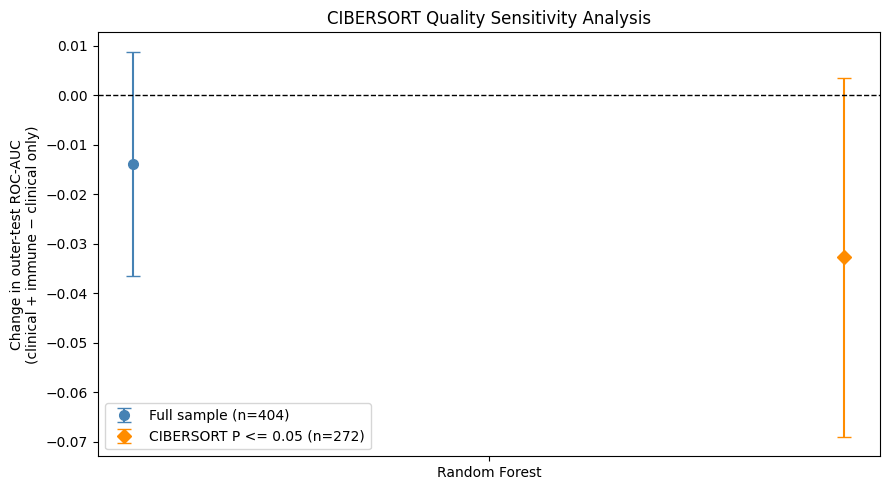

In [ ]:
# Plot the effect of adding raw immune features in the full and high-quality samples

plot_data = (
    sensitivity_change_comparison
    .set_index("model")
    .reindex(QUALITY_MODEL_NAMES)
)

x_positions = np.arange(
    len(QUALITY_MODEL_NAMES)
)

fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.errorbar(
    x_positions - 0.10,
    plot_data[
        "full_roc_auc_change_mean"
    ],
    yerr=plot_data[
        "full_roc_auc_change_sd"
    ],
    fmt="o",
    capsize=5,
    markersize=7,
    color="steelblue",
    label="Full sample (n=404)"
)

ax.errorbar(
    x_positions + 0.10,
    plot_data[
        "quality_roc_auc_change_mean"
    ],
    yerr=plot_data[
        "quality_roc_auc_change_sd"
    ],
    fmt="D",
    capsize=5,
    markersize=7,
    color="darkorange",
    label="CIBERSORT P <= 0.05 (n=272)"
)

ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_xticks(x_positions)
ax.set_xticklabels(
    QUALITY_MODEL_NAMES
)

ax.set_ylabel(
    "Change in outer-test ROC-AUC\n"
    "(clinical + immune − clinical only)"
)

ax.set_title(
    "CIBERSORT Quality Sensitivity Analysis"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "cibersort_quality_sensitivity_auc_change.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
quality_group_summary.to_csv(
    TABLE_DIR
    / "cibersort_quality_group_summary.csv",
    index=False
)

quality_stage_distribution.to_csv(
    TABLE_DIR
    / "cibersort_quality_stage_distribution.csv"
)

quality_grade_distribution.to_csv(
    TABLE_DIR
    / "cibersort_quality_grade_distribution.csv"
)

quality_results_df.to_csv(
    TABLE_DIR
    / "cibersort_quality_results_by_fold.csv",
    index=False
)

quality_performance_summary.to_csv(
    TABLE_DIR
    / "cibersort_quality_performance_summary.csv",
    index=False
)

quality_parameters_df.to_csv(
    TABLE_DIR
    / "cibersort_quality_best_parameters.csv",
    index=False
)

quality_oof_predictions.to_csv(
    TABLE_DIR
    / "cibersort_quality_oof_predictions.csv",
    index=False
)

quality_paired_comparison.to_csv(
    TABLE_DIR
    / "cibersort_quality_paired_comparison.csv",
    index=False
)

quality_improvement_summary.to_csv(
    TABLE_DIR
    / "cibersort_quality_improvement_summary.csv",
    index=False
)

sensitivity_change_comparison.to_csv(
    TABLE_DIR
    / "full_vs_quality_sensitivity_comparison.csv",
    index=False
)

print(
    "CIBERSORT quality sensitivity "
    "results were saved."
)

CIBERSORT quality sensitivity results were saved.


## 2.10, Failure analysis

In [ ]:
# Choose three failure cases

# Use the best-performing clinical-only Random Forest.
failure_source = (
    predictions_df[
        (predictions_df["model"]
         == "Random Forest")
        &
        (predictions_df["feature_set"]
         == "Clinical only")
    ]
    .copy()
)

# Add original clinical and survival information.
failure_source = (
    failure_source
    .merge(
        supervised[
            [
                "patient_id",
                "age_at_initial_pathologic_diagnosis",
                "gender",
                "ajcc_pathologic_tumor_stage",
                "histological_grade",
                "OS",
                "OS.time"
            ]
        ],
        on="patient_id",
        how="left",
        validate="one_to_one"
    )
)

failure_source["correct_prediction"] = (
    failure_source["actual_outcome"]
    == failure_source["predicted_class"]
)

# Keep only incorrect predictions.
incorrect_predictions = (
    failure_source[
        ~failure_source["correct_prediction"]
    ]
    .copy()
)

print(
    "Number of incorrect OOF predictions:",
    len(incorrect_predictions)
)

Number of incorrect OOF predictions: 98


In [ ]:
# Case A:
# Patient died within 3 years, but the model gave the highest incorrect survival score.
case_a = (
    incorrect_predictions[
        (incorrect_predictions["actual_outcome"] == 0)
        &
        (incorrect_predictions["predicted_class"] == 1)
    ]
    .sort_values(
        "prediction_score",
        ascending=False
    )
    .head(1)
)

# Case B:
# Patient survived at least 3 years, but the model gave the lowest survival score.
case_b = (
    incorrect_predictions[
        (incorrect_predictions["actual_outcome"] == 1)
        &
        (incorrect_predictions["predicted_class"] == 0)
    ]
    .sort_values(
        "prediction_score",
        ascending=True
    )
    .head(1)
)

assert len(case_a) == 1, (
    "No false-survivor case was found."
)

assert len(case_b) == 1, (
    "No false-death case was found."
)

# Do not select the same patient again.
already_selected = set(
    pd.concat(
        [case_a, case_b]
    )["patient_id"]
)

remaining_errors = (
    incorrect_predictions[
        ~incorrect_predictions["patient_id"]
        .isin(already_selected)
    ]
    .copy()
)

# First try to find an incorrect patient with missing stage or grade.
missing_clinical_errors = (
    remaining_errors[
        remaining_errors[
            "ajcc_pathologic_tumor_stage"
        ].isna()
        |
        remaining_errors[
            "histological_grade"
        ].isna()
    ]
    .copy()
)

if len(missing_clinical_errors) > 0:

    case_c = (
        missing_clinical_errors
        .head(1)
    )

    case_c_type = (
        "Incorrect prediction with "
        "missing clinical information"
    )

else:

    # If no missing-data error exists, select an error closest to the 0.50 decision boundary.
    remaining_errors["distance_from_threshold"] = (
        remaining_errors["prediction_score"]
        - 0.50
    ).abs()

    case_c = (
        remaining_errors
        .sort_values(
            "distance_from_threshold"
        )
        .head(1)
    )

    case_c_type = (
        "Borderline incorrect prediction"
    )

failure_cases = pd.concat(
    [case_a, case_b, case_c],
    ignore_index=True
)

failure_cases["case_label"] = [
    "Case A",
    "Case B",
    "Case C"
]

failure_cases["failure_type"] = [
    "High-confidence missed death",
    "High-confidence underestimated survival",
    case_c_type
]

failure_case_table = failure_cases[
    [
        "case_label",
        "failure_type",
        "patient_id",
        "outer_fold",
        "actual_outcome",
        "predicted_class",
        "prediction_score",
        "age_at_initial_pathologic_diagnosis",
        "gender",
        "ajcc_pathologic_tumor_stage",
        "histological_grade",
        "OS.time"
    ]
]

display(failure_case_table.round(3))

,case_label,failure_type,patient_id,outer_fold,actual_outcome,predicted_class,prediction_score,age_at_initial_pathologic_diagnosis,gender,ajcc_pathologic_tumor_stage,histological_grade,OS.time
0,Case A,High-confidence missed death,TCGA-BP-4353,4,0,1,0.942,61.0,MALE,Stage I,G2,375.0
1,Case B,High-confidence underestimated survival,TCGA-CJ-4637,1,1,0,0.084,52.0,FEMALE,Stage IV,G4,2227.0
2,Case C,Incorrect prediction with missing clinical inf...,TCGA-BP-4798,5,0,1,0.561,74.0,MALE,NaN,G4,334.0


In [ ]:
local_explanation_rows = []

for _, case in failure_cases.iterrows():

    patient_id = case["patient_id"]
    fold = int(case["outer_fold"])
    case_label = case["case_label"]

    # Retrieve the fitted outer-fold model.
    fitted_model = saved_models[
        ("Clinical only", fold)
    ]

    # Recover the training patients used for this fold.
    train_index, test_index = (
        outer_splits[fold - 1]
    )

    X_train_fold = (
        X_clinical
        .iloc[train_index]
        .copy()
    )

    # Get this patient's original feature row.
    patient_mask = (
        supervised["patient_id"]
        == patient_id
    )

    patient_X = (
        X_clinical[
            patient_mask
        ]
        .copy()
    )

    assert len(patient_X) == 1

    original_score = float(
        get_prediction_score(
            fitted_model,
            patient_X
        )[0]
    )

    for feature in clinical_features:

        changed_X = patient_X.copy()

        # Numerical variable: use the training median.
        if feature in clinical_numeric_features:

            reference_value = (
                X_train_fold[feature]
                .median()
            )

        # Categorical variable: use the training mode.
        else:

            mode_values = (
                X_train_fold[feature]
                .mode(dropna=True)
            )

            if len(mode_values) > 0:
                reference_value = (
                    mode_values.iloc[0]
                )
            else:
                reference_value = np.nan

        original_value = (
            patient_X[feature]
            .iloc[0]
        )

        changed_X.loc[
            changed_X.index[0],
            feature
        ] = reference_value

        changed_score = float(
            get_prediction_score(
                fitted_model,
                changed_X
            )[0]
        )

        local_explanation_rows.append({
            "case_label": case_label,
            "patient_id": patient_id,
            "feature": feature,
            "original_value": original_value,
            "training_reference_value":
                reference_value,
            "original_survival_score":
                original_score,
            "score_after_replacement":
                changed_score,
            "score_change":
                changed_score
                - original_score
        })

local_explanation_df = pd.DataFrame(
    local_explanation_rows
)

local_explanation_df[
    "absolute_score_change"
] = (
    local_explanation_df["score_change"]
    .abs()
)

display(
    local_explanation_df
    .sort_values(
        [
            "case_label",
            "absolute_score_change"
        ],
        ascending=[
            True,
            False
        ]
    )
    .round(3)
)

,case_label,patient_id,feature,original_value,training_reference_value,original_survival_score,score_after_replacement,score_change,absolute_score_change
3,Case A,TCGA-BP-4353,histological_grade,G2,G3,0.942,0.778,-0.165,0.165
0,Case A,TCGA-BP-4353,age_at_initial_pathologic_diagnosis,61.0,60.0,0.942,0.942,-0.000,0.000
1,Case A,TCGA-BP-4353,gender,MALE,MALE,0.942,0.942,0.000,0.000
2,Case A,TCGA-BP-4353,ajcc_pathologic_tumor_stage,Stage I,Stage I,0.942,0.942,0.000,0.000
6,Case B,TCGA-CJ-4637,ajcc_pathologic_tumor_stage,Stage IV,Stage I,0.084,0.601,0.517,0.517
5,Case B,TCGA-CJ-4637,gender,FEMALE,MALE,0.084,0.244,0.159,0.159
7,Case B,TCGA-CJ-4637,histological_grade,G4,G3,0.084,0.156,0.072,0.072
4,Case B,TCGA-CJ-4637,age_at_initial_pathologic_diagnosis,52.0,61.0,0.084,0.138,0.054,0.054
11,Case C,TCGA-BP-4798,histological_grade,G4,G2,0.561,0.628,0.067,0.067
8,Case C,TCGA-BP-4798,age_at_initial_pathologic_diagnosis,74.0,61.0,0.561,0.556,-0.005,0.005


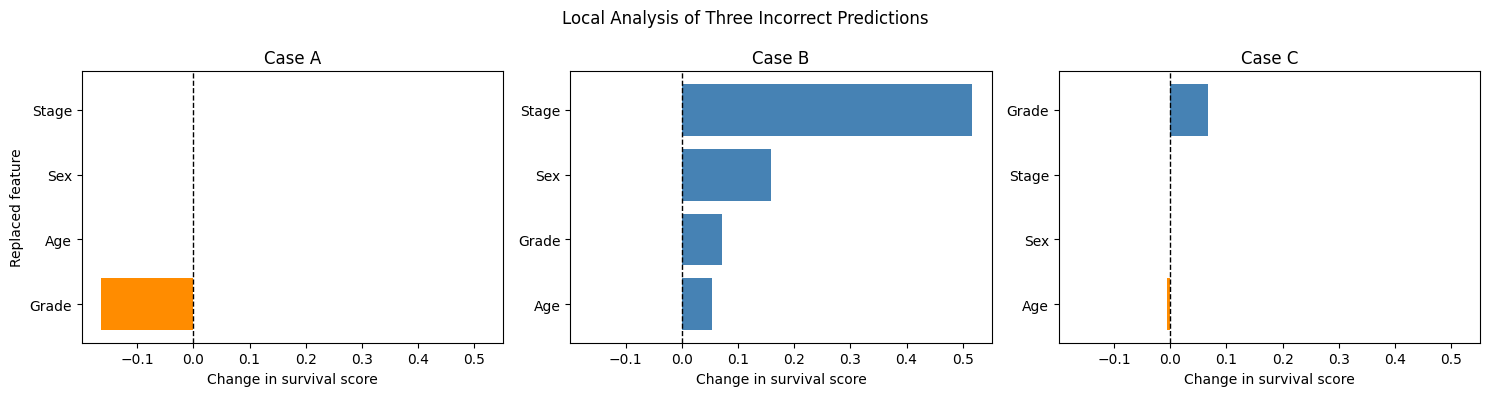

In [ ]:
feature_display_names = {
    "age_at_initial_pathologic_diagnosis":
        "Age",
    "gender":
        "Sex",
    "ajcc_pathologic_tumor_stage":
        "Stage",
    "histological_grade":
        "Grade"
}

local_explanation_df["feature_label"] = (
    local_explanation_df["feature"]
    .map(feature_display_names)
)

figure, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4),
    sharex=True
)

for axis, case_label in zip(
    axes,
    ["Case A", "Case B", "Case C"]
):

    plot_data = (
        local_explanation_df[
            local_explanation_df["case_label"]
            == case_label
        ]
        .sort_values("score_change")
    )

    colors = np.where(
        plot_data["score_change"] >= 0,
        "steelblue",
        "darkorange"
    )

    axis.barh(
        plot_data["feature_label"],
        plot_data["score_change"],
        color=colors
    )

    axis.axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    axis.set_title(case_label)
    axis.set_xlabel(
        "Change in survival score"
    )

axes[0].set_ylabel("Replaced feature")

figure.suptitle(
    "Local Analysis of Three Incorrect Predictions"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "rf_failure_case_local_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **Part 3: Unsupervised Learning**